# IRL Model Analysis

- based on `data/data_integrated.csv`, `irl_models/models_integrated.csv`
- saves `data_integrated_final.csv`, `*_full_integrated.npz`, `full_traj_dict.npz`

## Setup

### Load

In [100]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from scipy import stats
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_rel, ttest_ind, linregress, pearsonr, t

import seaborn as sns

from utils_irl_models import load_trained_model, load_traj_per_episode

### Data & Models

In [65]:
df = pd.read_csv("data/data_integrated.csv", encoding="utf-8-sig")
models = pd.read_csv("irl_models/models_integrated.csv")
if set(df["subj_id"]) != set(models["subj_id"]):
    raise Exception("invalid subject list")

print(f"N={len(df)}")

N=282


In [66]:
model_dict = {}
desktop_subjIds = []
web_subjIds = []
for idx, model in models.iterrows():
    subjId = model["subj_id"]
    rounds = model["rounds"]
    model_info = {
        "subjId": subjId,
        "web": model["sample_type"] == "web",
        "rounds": rounds,
    }
    model_dict[subjId] = model_info
    if model["sample_type"] == "web":
       web_subjIds.append(subjId)
    else:
       desktop_subjIds.append(subjId)
    
full_subjIds = list(model_dict.keys())
print(f"Combined sample (N={len(model_dict)})")
print(f"Web sample (N={len(web_subjIds)})")
print(f"Desktop sample (N={len(desktop_subjIds)})")
print(f"N={len(full_subjIds)}={len(desktop_subjIds)}+{len(web_subjIds)}")

Combined sample (N=282)
Web sample (N=229)
Desktop sample (N=53)
N=282=53+229


### Trajectory

In [67]:
traj_save_path = "data/full_traj_dict.npz"

def load_traj(model, web):
    obs_t, next_obs_t, actions, rewards, infos = load_traj_per_episode(
        subjId=model["subjId"],
        web=model["web"],
        remove_initial_noop=True,
    )
    T = len(actions)
    dones = np.zeros(T, dtype=np.float32)

    # target_road_obs[0][0] = target_road_uid
    # target_road_obs[0][1] = road_size (2 or 4)
    # target_road_obs[0][2] = penalty
    # target_road_obs[0][3] = has_crosswalk (0=not exist vs 1=exist)
    target_road_obs = []
    for info in infos:
        target_road_uid = info["play_infos"]["map"]["target_road_uid"]
        target_road = None
        for road in info["episode_metadata"]["episode_configuration"]["roads"]["roads"]:
            if road["uid"] == target_road_uid:
                target_road = road
                break
        assert target_road is not None
        if web:
            road_size = target_road["bottomY"] - target_road["top_y"] + 1
        else:
            road_size = target_road["bottom_y"] - target_road["top_y"] + 1
        penalty = target_road["penalty"]
        has_crosswalk = 0 if target_road["crosswalk"] is None else 1
        target_road_obs.append([target_road_uid, road_size, penalty, has_crosswalk])
    return actions, obs_t, next_obs_t, rewards, dones, target_road_obs

# heavy computation
def save_full_traj(save_path):
    acts, obs_t_list, next_obs_list, rews, dns, target_road_obs_list = [], [], [], [], [], []
    for subj_id in model_dict.keys():
        model = model_dict[subj_id]
        actions, obs_t, next_obs_t, rewards, dones, target_road_obs = load_traj(model, web=model["web"])
        acts.append(actions)
        obs_t_list.append(obs_t) # (T, obs_dim)
        next_obs_list.append(next_obs_t) # (T, obs_dim)
        rews.append(rewards)
        dns.append(dones)
        target_road_obs_list.append(target_road_obs)

    full_traj_dict = {
        "actions": np.concatenate(acts),
        "obs": np.concatenate(obs_t_list),
        "next_obs": np.concatenate(next_obs_list),
        "rewards": np.concatenate(rews),
        "dones": np.concatenate(dns),
        "target_road_obs": np.concatenate(target_road_obs_list)
    }

    save_dir = os.path.dirname(save_path)
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
    np.savez_compressed(save_path, **full_traj_dict)

if not os.path.exists(traj_save_path):
    save_full_traj(traj_save_path)

with np.load(traj_save_path, allow_pickle=False) as data:
    full_traj_dict = {
        key: data[key] for key in data.files
    }

### IRL reward

In [68]:
def calculate_rewards(reward_net, obs, actions, dones):
    rews = reward_net.predict_processed(obs, actions, obs, dones)
    rews = np.asarray(rews, dtype=np.float32).squeeze()
    return rews

def save_irl_reward(model):
    subjId = model['subjId']
    train_rounds=model['rounds']

    save_dir = f"irl_models/{subjId}/rewnet_8_8_best/rewards"
    os.makedirs(save_dir, exist_ok=True)
    filename = f"irl_reward{train_rounds}_full_integrated.npz"
    save_path = os.path.join(save_dir, filename)

    if os.path.exists(save_path):
        return

    reward_net, gen_algo = load_trained_model(subj_id=subjId, train_rounds=train_rounds)

    actions = full_traj_dict["actions"]
    obs_t = full_traj_dict["obs"]
    dones = full_traj_dict["dones"]

    # calculate IRL reward
    rews = calculate_rewards(reward_net, obs_t, actions, dones)
    mu = float(rews.mean())
    sigma = float(rews.std())
    rews_norm = (rews - mu) / sigma
    np.savez(save_path, irl_reward_raw=rews, irl_reward_norm=rews_norm)
    
for subj_id in full_subjIds:
    save_irl_reward(model=model_dict[subj_id])

In [69]:
def load_irl_rewards(subjId):
    model = model_dict[subjId]
    subjId = model['subjId']
    train_rounds=model['rounds']

    save_dir = f"irl_models/{subjId}/rewnet_8_8_best/rewards"
    filename = f"irl_reward{train_rounds}_full_integrated.npz"
    save_path = os.path.join(save_dir, filename)
    npz = np.load(save_path)

    irl_data = {k: npz[k] for k in npz.files}
    irl_data["obs"] = full_traj_dict["obs"]
    irl_data["target_road_obs"] = full_traj_dict["target_road_obs"]
    irl_data["actions"] = full_traj_dict["actions"]
    irl_data["next_obs"] = full_traj_dict["next_obs"]
    irl_data["dones"] = full_traj_dict["dones"]
    irl_data["rewards"] = full_traj_dict["rewards"]

    irl_data["states"] = {
        "obs": irl_data["obs"],
        "next_obs": irl_data["next_obs"],
        "actions": irl_data["actions"],
        "target_road_obs": irl_data["target_road_obs"],
    }
    return irl_data

irl_reward_dict = dict()
for subj_id in full_subjIds:
    irl_data = load_irl_rewards(subj_id)
    irl_reward_dict[subj_id] = irl_data

### Conditions

In [70]:
from enum import Enum

class Action(Enum):
    NOTHING = 0
    UP = 1
    DOWN = 2
    RIGHT = 3
    LEFT = 4

def calculate_mean_IRL_reward_by_conditions(
    subjId,
    conditions=None, # [func(states)], AND condition
    or_conditions=None, # [func(states)], OR condition
    action_conditions=None, # [Action], OR condition
    reward_condition=None, # func(rewards)
    use_reward_norm=True,
    state_only=False,
    verbose=False,
    conditions_text="",
):
    irl_data = irl_reward_dict[subjId]
    states = irl_data["states"]
    rewards = irl_data["rewards"]
    actions = irl_data["actions"] # shape (T,)
    if state_only:
        rews_norm = None # irl_data["rews_norm_per_actions"][0] # No-op # shape (T,)
    elif use_reward_norm:
        rews_norm = irl_data["irl_reward_norm"] # shape (T,)
    else:
        rews_norm = irl_data["irl_reward_raw"] # shape (T,)
    
    T = len(actions) # number of transitions
    if conditions is None and or_conditions is None:
        mask = np.ones(T, dtype=bool) # all true, no filtering based on states
    elif conditions is not None:
        mask = np.ones(T, dtype=bool)
        # for feat_idx, val in conditions.items():
        for condition in conditions:            
            mask &= condition(states) # AND [:, feat_idx] == val) # AND
    elif or_conditions is not None:
        mask = None
        for condition in or_conditions:
            cond_mask = condition(states)
            if mask is None:
                mask = cond_mask.copy()
            else:
                mask |= cond_mask # OR
    else:
        raise Exception("conditions and or_conditions cannot be applied together")

    if action_conditions is not None:
        action_conditions_num = [a.value for a in action_conditions]
        mask &= np.isin(actions, action_conditions_num)

    if reward_condition is not None:
        mask &= reward_condition(rewards)
    
    selected_rews = rews_norm[mask]
    mean = float(np.mean(selected_rews)) if selected_rews.size > 0 else np.nan

    if verbose:
        print(f"[subj {subjId}] E[r | {conditions_text}] = {mean:.4f} (n={mask.sum()})")
        if mean is np.nan:
            print(f"{subjId}: {mean}")

    return mean

In [71]:
def always_true_cond(states):
    return states["obs"][:, 0] >= 0

# reward_condition
def run_over(rewards):
    return rewards < 0 # last action before death check
def alive(rewards):
    return rewards >= 0
def road_crossed(rewards):
    return rewards > 0
def no_reward(rewards):
    return rewards == 0
    
def time_left_less_than_cond(i):
    def time_left_cond(states):
        return states["obs"][:, 0] < i
    return time_left_cond
def time_left_greater_than_cond(i):
    def time_left_cond(states):
        return states["obs"][:, 0] > i
    return time_left_cond
def time_left_less_or_equal_cond(i):
    def time_left_cond(states):
        return states["obs"][:, 0] <= i
    return time_left_cond
def time_left_greater_or_equal_cond(i):
    def time_left_cond(states):
        return states["obs"][:, 0] >= i
    return time_left_cond
def time_left_cond_bins(bin_count):
    conds = []
    conds.append([time_left_greater_than_cond((bin_count-1)/bin_count)])
    for i in range(bin_count-2):
        conds.append([time_left_greater_than_cond((bin_count-2-i)/bin_count), time_left_less_or_equal_cond((bin_count-1-i)/bin_count)])
    conds.append([time_left_less_or_equal_cond(1/bin_count)])
    return conds

def finish_line_visible_cond(states):
    return states["obs"][:, 1] > 0.1 # >= 0.2
def finish_line_not_visible_cond(states):
    return states["obs"][:, 1] == 0

def safe_zone_cond(states):
    return states["obs"][:, 5] == 0
def next_safe_zone_cond(states):
    return states["next_obs"][:, 5] == 0
def danger_zone_cond(states):
    return states["obs"][:, 5] == 1
def next_danger_zone_cond(states):
    return states["next_obs"][:, 5] == 1
def inside_crosswalk_cond(states):
    return states["obs"][:, 8] == 1
def outside_crosswalk_cond(states):
    return states["obs"][:, 8] == 0
def next_inside_crosswalk_cond(states):
    return states["next_obs"][:, 8] == 1
def next_outside_crosswalk_cond(states):
    return states["next_obs"][:, 8] == 0

def crosswalk_not_visible_cond(states):
    return states["obs"][:, 13] == 0
def crosswalk_visible_cond(states):
    return states["obs"][:, 13] == 1

# - obs[15]: distance from the end of the road
# - 0.0 = can escape the road after moving up 1 more tile
# - 0.25 = can escape the road after moving up 2 more tile
# - 0.50 = can escape the road after moving up 3 more tile
# - 0.75 = can escape the road after moving up 4 more tile
# - 1.0 = in the safe zone, before crossing the road
def dist1_from_road_end_cond(states):
    return states["obs"][:, 15] == 1/4
def dist2_from_road_end_cond(states):
    return states["obs"][:, 15] == 2/4
def dist3_from_road_end_cond(states):
    return states["obs"][:, 15] == 3/4
def dist4_from_road_end_cond(states):
    return states["obs"][:, 15] == 4/4

# - obs[16]: distance from the start of the road
# - 0.0 = in the safe zone, before crossing the road
# - 0.25 = agent can escape the road after moving down 1 more tile
# - 0.50 = agent can escape the road after moving down 2 more tile
# - 0.75 = agent can escape the road after moving down 3 more tile
# - 1.0 = agent can escape the road after moving down 4 more tile
def dist1_from_road_start_cond(states):
    return states["obs"][:, 16] == 1/4
def dist2_from_road_start_cond(states):
    return states["obs"][:, 16] == 2/4
def dist3_from_road_start_cond(states):
    return states["obs"][:, 16] == 3/4
def dist4_from_road_start_cond(states):
    return states["obs"][:, 16] == 4/4

def low_penalty_road_cond(states):
    return states["obs"][:, 14] == 0.1
def low_or_mid_penalty_road_cond(states):
    mask = low_penalty_road_cond(states)
    mask |= mid_penalty_road_cond(states)
    return mask
def mid_penalty_road_cond(states):
    return states["obs"][:, 14] == 0.5
def mid_or_high_penalty_road_cond(states):
    mask = mid_penalty_road_cond(states)
    mask |= high_penalty_road_cond(states)
    return mask
def high_penalty_road_cond(states):
    return states["obs"][:, 14] == 1.0

def short_road_condition(states):
    # target_road_obs[0][1] = road_size (2 or 4)
    return states["target_road_obs"][:, 1] == 2
def long_road_condition(states):
    # target_road_obs[0][1] = road_size (2 or 4)
    return states["target_road_obs"][:, 1] == 4

def not_last_road_condition(states):
    return states["target_road_obs"][:, 0] != 1

def last_road_condition(states):
    return states["target_road_obs"][:, 0] == 1

def car_density_cond(i):
    def cond(states):
        return states["obs"][:, 17] == i/6
    return cond

# car_density_cond_lte(2) # 0,1,2
# car_density_cond_gte(3) # 3,4,5,6
def car_density_cond_lte(i):
    def cond(states):
        return states["obs"][:, 17] <= i/6
    return cond
def car_density_cond_gte(i):
    def cond(states):
        return states["obs"][:, 17] >= i/6
    return cond

def no_op(states):
    return states["actions"] == 0
def moving(states):
    return states["actions"] > 0
def move_up(states):
    return states["actions"] == 1
def move_down(states):
    return states["actions"] == 2
def move_right(states):
    return states["actions"] == 3
def move_left(states):
    return states["actions"] == 4
def move_sideways(states):
    mask = move_right(states)
    mask |= move_left(states)
    return mask
    
def car_in_front_NW_cond(states):
    return states["obs"][:, 33] >= 1
def car_in_front_N_cond(states):
    return states["obs"][:, 34] >= 1
def car_not_in_front_N_cond(states):
    return states["obs"][:, 34] <= 0    
def car_in_front_NE_cond(states):
    return states["obs"][:, 35] >= 1
def car_in_front_cond(states):
    mask = car_in_front_NW_cond(states)
    mask |= car_in_front_N_cond(states)
    mask |= car_in_front_NE_cond(states)
    return mask

move_toward_car_in_front_conds = [move_up, car_in_front_cond]
move_toward_car_in_front_NW_conds = [move_up, car_in_front_NW_cond]
move_toward_car_in_front_N_conds = [move_up, car_in_front_N_cond]
move_toward_car_in_front_NE_conds = [move_up, car_in_front_NE_cond]

# obs[79]: left closest car position 1 rows ahead (tail distance)
# obs[83]: right closest car position 1 rows ahead (tail distance)
# - distance until car tail (closest dangerous car; lower = safer)
#   - 0 = no car in front of the agent
#   - 0 ~ 1 = distance from the tail of the car that is in front of the agent (decreases as car passes)
def gen_car_tail_distance_cond(min_val, max_val):
    def car_tail_distance_cond(states):
        mask1 = states["obs"][:, 79] > min_val
        mask1 &= states["obs"][:, 79] <= max_val
        mask2 = states["obs"][:, 83] > min_val
        mask2 &= states["obs"][:, 83] <= max_val
        mask1 |= mask2
        return mask1
    return car_tail_distance_cond

def move_up_at_car_tail_cond_bins(bin_count, add_no_car_in_front=True):
    conds = []
    if add_no_car_in_front:
        conds.append([car_not_in_front_N_cond, move_up])
    for i in range(bin_count):
        conds.append([gen_car_tail_distance_cond(i/bin_count, (i+1)/bin_count), car_in_front_N_cond, move_up])
    return conds

def next_lane_car_tail_distance_cond_bins(bin_count):
    conds = []
    for i in range(bin_count):
        conds.append([gen_car_tail_distance_cond(i/bin_count, (i+1)/bin_count)])
    return conds

# - obs[89]: left closest car info same row (head closeness)
# - obs[93]: right closest car info same row (head closeness)
# - closeness of car head (closest dangerous cars)
#  - 0 = no car coming toward the agent
#  - 0 ~ 1 = closeness of the head of the car coming toward the agent
#  - 1 = car right in front of the agent
def same_lane_left_car_exists_cond(states):
    return states["obs"][:, 89] > 0
def same_lane_right_car_exists_cond(states):
    return states["obs"][:, 93] > 0
def same_lane_car_exists_cond(states):
    mask = same_lane_left_car_exists_cond(states)
    mask |= same_lane_right_car_exists_cond(states)
    return mask

def gen_left_car_closeness_cond(min_val, max_val):
    def left_car_closeness_cond(states):
        mask = states["obs"][:, 89] > min_val
        mask &= states["obs"][:, 89] <= max_val
        return mask
    return left_car_closeness_cond

def left_car_closeness_cond_bins(bin_count):
    conds = []
    for i in range(bin_count):
        conds.append([gen_left_car_closeness_cond(i/bin_count, (i+1)/bin_count)])
    return conds

def gen_right_car_closeness_cond(min_val, max_val):
    def right_car_closeness_cond(states):
        mask = states["obs"][:, 93] > min_val
        mask &= states["obs"][:, 93] <= max_val
        return mask
    return right_car_closeness_cond

def right_car_closeness_cond_bins(bin_count):
    conds = []
    for i in range(bin_count):
        conds.append([gen_right_car_closeness_cond(i/bin_count, (i+1)/bin_count)])
    return conds

def gen_same_lane_car_closeness_cond(min_val, max_val):
    def car_closeness_cond(states):
        mask1 = gen_left_car_closeness_cond(min_val, max_val)(states)
        mask2 = gen_right_car_closeness_cond(min_val, max_val)(states)
        mask1 |= mask2
        return mask1
    return car_closeness_cond

def same_lane_car_closeness_cond_bins(bin_count):
    conds = []
    for i in range(bin_count):
        conds.append([gen_same_lane_car_closeness_cond(i/bin_count, (i+1)/bin_count)])
    return conds

#######

def at_least_one_max_speed_car_exists_in_front_cond(states):
    mask = states["obs"][:, 44] == 1 # max speed (left closest car info 4 rows ahead)
    mask |= states["obs"][:, 48] == 1 # max speed (right closest car info 4 rows ahead)
    mask |= states["obs"][:, 56] == 1 # max speed (left closest car info 3 rows ahead)
    mask |= states["obs"][:, 60] == 1 # max speed (right closest car info 3 rows ahead)
    mask |= states["obs"][:, 68] == 1 # max speed (left closest car info 2 rows ahead)
    mask |= states["obs"][:, 72] == 1 # max speed (right closest car info 2 rows ahead)
    mask |= states["obs"][:, 80] == 1 # max speed (left closest car info 1 rows ahead)
    mask |= states["obs"][:, 84] == 1 # max speed (right closest car info 1 rows ahead)
    return mask

def encoming_car_in_front4_cond_at_least_one(states):
    mask = states["obs"][:, 18] > 0 # number of cars coming toward the agent (NW)
    mask |= states["obs"][:, 19] > 0 # number of cars coming toward the agent (NE)
    return mask

def encoming_car_in_front4_cond_v2(states):
    mask = states["obs"][:, 41] > 0 # left closest car info 4 rows ahead (head closeness)
    mask |= states["obs"][:, 45] > 0 # right closest car info 4 rows ahead (head closeness)
    mask |= states["obs"][:, 53] > 0 # left closest car info 3 rows ahead (head closeness)
    mask |= states["obs"][:, 57] > 0 # right closest car info 3 rows ahead (head closeness)
    mask |= states["obs"][:, 65] > 0 # left closest car info 2 rows ahead (head closeness)
    mask |= states["obs"][:, 69] > 0 # right closest car info 2 rows ahead (head closeness)
    mask |= states["obs"][:, 77] > 0 # left closest car info 1 rows ahead (head closeness)
    mask |= states["obs"][:, 81] > 0 # right closest car info 1 rows ahead (head closeness)
    return mask

def encoming_car_in_front4_cond(states):
    mask = states["obs"][:, 44] > 0 # left closest car info 4 rows ahead (speed)
    mask |= states["obs"][:, 48] > 0 # right closest car info 4 rows ahead (speed)
    mask |= states["obs"][:, 56] > 0 # left closest car info 3 rows ahead (speed)
    mask |= states["obs"][:, 60] > 0 # right closest car info 3 rows ahead (speed)
    mask |= states["obs"][:, 68] > 0 # left closest car info 2 rows ahead (speed)
    mask |= states["obs"][:, 72] > 0 # right closest car info 2 rows ahead (speed)
    mask |= states["obs"][:, 80] > 0 # left closest car info 1 rows ahead (speed)
    mask |= states["obs"][:, 84] > 0 # right closest car info 1 rows ahead (speed)
    return mask

def encoming_car_in_front3_cond(states):
    mask = states["obs"][:, 56] > 0 # left closest car info 3 rows ahead (speed)
    mask |= states["obs"][:, 60] > 0 # right closest car info 3 rows ahead (speed)
    mask |= states["obs"][:, 68] > 0 # left closest car info 2 rows ahead (speed)
    mask |= states["obs"][:, 72] > 0 # right closest car info 2 rows ahead (speed)
    mask |= states["obs"][:, 80] > 0 # left closest car info 1 rows ahead (speed)
    mask |= states["obs"][:, 84] > 0 # right closest car info 1 rows ahead (speed)
    return mask

def encoming_car_in_front2_cond(states):
    mask = states["obs"][:, 68] > 0 # left closest car info 2 rows ahead (speed)
    mask |= states["obs"][:, 72] > 0 # right closest car info 2 rows ahead (speed)
    mask |= states["obs"][:, 80] > 0 # left closest car info 1 rows ahead (speed)
    mask |= states["obs"][:, 84] > 0 # right closest car info 1 rows ahead (speed)
    return mask

def encoming_car_in_front_cond(states):
    mask = states["obs"][:, 80] > 0 # left closest car info 1 rows ahead (speed)
    mask |= states["obs"][:, 84] > 0 # right closest car info 1 rows ahead (speed)
    return mask

def encoming_car_in_front_lane_not_blocking_cond(states):
    mask = states["obs"][:, 77] < 1 # left closest car position 1 rows ahead (head closeness)
    mask &= states["obs"][:, 81] < 1 # right closest car position 1 rows ahead (head closeness)
    return mask

def encoming_max_speed_car_in_front2_cond(states):
    mask = states["obs"][:, 68] == 1 # left closest car info 2 rows ahead
    mask |= states["obs"][:, 72] == 1 # right closest car info 2 rows ahead
    mask |= states["obs"][:, 80] == 1 # left closest car info 1 rows ahead
    mask |= states["obs"][:, 84] == 1 # right closest car info 1 rows ahead
    return mask

def encoming_max_speed_car_in_front_cond(states):
    mask = states["obs"][:, 80] == 1 # left closest car info 1 rows ahead
    mask |= states["obs"][:, 84] == 1 # right closest car info 1 rows ahead
    return mask

def encoming_max_speed_car_in_same_lane_cond(states):
    mask = states["obs"][:, 92] == 1 # left closest car info same row
    mask |= states["obs"][:, 96] == 1 # right closest car info same row
    return mask

#######

def move_toward_crosswalk_depth1(states):
    closer_to_right_crosswalk = states["obs"][:, 25] < states["next_obs"][:, 25] # closeness to closest crosswalk (RIGHT)
    closer_to_left_crosswalk = states["obs"][:, 26] < states["next_obs"][:, 26] # closeness to closest crosswalk (LEFT)
    return closer_to_right_crosswalk | closer_to_left_crosswalk

def move_toward_crosswalk_depth2_only(states):
    closer_to_right_crosswalk = states["obs"][:, 28] < states["next_obs"][:, 28] # closeness to 2nd closest crosswalk (RIGHT)
    closer_to_left_crosswalk = states["obs"][:, 29] < states["next_obs"][:, 29] # closeness to 2nd closest crosswalk (LEFT)
    return closer_to_right_crosswalk | closer_to_left_crosswalk

def move_toward_crosswalk_depth2(states):
    mask = move_toward_crosswalk_depth1(states)
    closer_to_right_crosswalk = states["obs"][:, 28] < states["next_obs"][:, 28] # closeness to 2nd closest crosswalk (RIGHT)
    closer_to_left_crosswalk = states["obs"][:, 29] < states["next_obs"][:, 29] # closeness to 2nd closest crosswalk (LEFT)
    return mask | closer_to_right_crosswalk | closer_to_left_crosswalk

def move_toward_next_crosswalks(states):
    mask = move_toward_crosswalk_depth2_only(states)
    closer_to_right_crosswalk = states["obs"][:, 31] < states["next_obs"][:, 31] # closeness to 3rd closest crosswalk (RIGHT)
    closer_to_left_crosswalk = states["obs"][:, 32] < states["next_obs"][:, 32] # closeness to 3rd closest crosswalk (LEFT)
    return mask | closer_to_right_crosswalk | closer_to_left_crosswalk

def move_toward_crosswalk_depth3(states):
    mask = move_toward_crosswalk_depth2(states)
    closer_to_right_crosswalk = states["obs"][:, 31] < states["next_obs"][:, 31] # closeness to 3rd closest crosswalk (RIGHT)
    closer_to_left_crosswalk = states["obs"][:, 32] < states["next_obs"][:, 32] # closeness to 3rd closest crosswalk (LEFT)
    return mask | closer_to_right_crosswalk | closer_to_left_crosswalk

def move_sideways_to_activate_crosswalk(states):
    mask = move_right(states)
    mask |= move_left(states)
    mask &= outside_crosswalk_cond(states)
    mask &= next_inside_crosswalk_cond(states)
    return mask

###########

# - obs[15]: distance from the end of the road
# - 0.0 = can escape the road after moving up 1 more tile
# - 0.25 = can escape the road after moving up 2 more tile
# - 0.50 = can escape the road after moving up 3 more tile
# - 0.75 = can escape the road after moving up 4 more tile
# - 1.0 = in the safe zone, before crossing the road
def dist_range_from_road_end_cond(max_tile_cnt):
    def cond(states):
        return states["obs"][:, 15] <= (max_tile_cnt-1)/4
    return cond
def dist_range_from_road_end_cond_min(min_tile_cnt):
    def cond(states):
        return states["obs"][:, 15] >= (min_tile_cnt-1)/4
    return cond
def dist1_from_road_end_cond(states):
    return states["obs"][:, 15] == 0
def dist2_from_road_end_cond(states):
    return states["obs"][:, 15] == 1/4
def dist3_from_road_end_cond(states):
    return states["obs"][:, 15] == 2/4
def dist4_from_road_end_cond(states):
    return states["obs"][:, 15] == 3/4

# - obs[16]: distance from the start of the road
# - 0.0 = in the safe zone, before crossing the road
# - 0.25 = agent can escape the road after moving down 1 more tile
# - 0.50 = agent can escape the road after moving down 2 more tile
# - 0.75 = agent can escape the road after moving down 3 more tile
# - 1.0 = agent can escape the road after moving down 4 more tile
def dist_range_from_road_start_cond(max_tile_cnt):
    def cond(states):
        return (states["obs"][:, 16] <= max_tile_cnt/4)
    return cond
def dist_range_from_road_start_cond_min(min_tile_cnt):
    def cond(states):
        return (states["obs"][:, 16] >= min_tile_cnt/4)
    return cond
def dist1_from_road_start_cond(states):
    return states["obs"][:, 16] == 1/4
def dist2_from_road_start_cond(states):
    return states["obs"][:, 16] == 2/4
def dist3_from_road_start_cond(states):
    return states["obs"][:, 16] == 3/4
def dist4_from_road_start_cond(states):
    return states["obs"][:, 16] == 4/4

##############

# cur lane car
def no_encoming_car_in_same_lane(states):
    mask = (states["obs"][:, 89] == 0)  # left closest car position same row (head closeness)
    mask |= (states["obs"][:, 93] == 0) # right closest car position same row (head closeness)
    return mask

def encoming_car_in_same_lane_thresh(thresh):
    def cond(states):
        mask = (states["obs"][:, 89] > thresh[0]) & (states["obs"][:, 89] < thresh[1]) # left closest car position same row (head closeness)
        mask |= (states["obs"][:, 93] > thresh[0]) & (states["obs"][:, 93] < thresh[1]) # right closest car position same row (head closeness)
        return mask
    return cond

def run_over_obs_cond(states):
    mask = (states["obs"][:, 89] >= 1)  # left closest car position same row (head closeness)
    mask |= (states["obs"][:, 93] >= 1) # right closest car position same row (head closeness)
    return mask

def encoming_car_in_same_lane_thresh_bins(bin_count, full=False, base_conds=[always_true_cond]):
    conds = []
    if full:
        conds.append([no_encoming_car_in_same_lane] + base_conds)
    for i in range(bin_count):
        conds.append([encoming_car_in_same_lane_thresh((i/bin_count, (i+1)/bin_count))] + base_conds)
    if full:
        conds.append([run_over_obs_cond] + base_conds)
    return conds

# next lane car
def no_encoming_car_in_front1(states):
    mask = (states["obs"][:, 77] == 0) # left closest car position 1 rows ahead (head closeness)
    mask |= (states["obs"][:, 81] == 0) # right closest car position 1 rows ahead (head closeness)
    return mask

def encoming_car_in_front1_thresh(thresh):
    def cond(states):
        mask = (states["obs"][:, 77] > thresh[0]) & (states["obs"][:, 77] < thresh[1]) # left closest car position 1 rows ahead (head closeness)
        mask |= (states["obs"][:, 81] > thresh[0]) & (states["obs"][:, 81] < thresh[1]) # right closest car position 1 rows ahead (head closeness)
        return mask
    return cond

def encoming_car_in_front1_thresh_bins(bin_count, full=False, base_conds=[always_true_cond]):
    conds = []
    if full:
        conds.append([no_encoming_car_in_front1] + base_conds)
    for i in range(bin_count):
        conds.append([encoming_car_in_front1_thresh((i/bin_count, (i+1)/bin_count))] + base_conds)
    if full:
        conds.append([car_in_front_N_cond] + base_conds)
    return conds

# car 2 lanes ahead
def no_encoming_car_in_front2(states):
    mask = (states["obs"][:, 65] == 0) # left closest car position 2 rows ahead (head closeness)
    mask |= (states["obs"][:, 69] == 0) # right closest car position 2 rows ahead (head closeness)
    return mask

def encoming_car_in_front2_thresh(thresh):
    def cond(states):
        mask = (states["obs"][:, 65] > thresh[0]) & (states["obs"][:, 65] < thresh[1]) # left closest car position 2 rows ahead (head closeness)
        mask |= (states["obs"][:, 69] > thresh[0]) & (states["obs"][:, 69] < thresh[1]) # right closest car position 2 rows ahead (head closeness)
        return mask
    return cond

def car_in_front2(states):
    mask = (states["obs"][:, 65] >= 1) # left closest car position 2 rows ahead (head closeness)
    mask |= (states["obs"][:, 69] >= 1) # right closest car position 2 rows ahead (head closeness)
    return mask

def encoming_car_in_front2_thresh_bins(bin_count, full=False, base_conds=[always_true_cond]):
    conds = []
    if full:
        conds.append([no_encoming_car_in_front2] + base_conds)
    for i in range(bin_count):
        conds.append([encoming_car_in_front2_thresh((i/bin_count, (i+1)/bin_count))] + base_conds)
    if full:
        conds.append([car_in_front2] + base_conds)
    return conds

def encoming_car_in_front1or2_thresh(thresh):
    def cond(states):
        mask = (states["obs"][:, 65] > thresh[0]) & (states["obs"][:, 65] < thresh[1]) # left closest car position 2 rows ahead (head closeness)
        mask |= (states["obs"][:, 69] > thresh[0]) & (states["obs"][:, 69] < thresh[1]) # right closest car position 2 rows ahead (head closeness)
        mask |= (states["obs"][:, 77] > thresh[0]) & (states["obs"][:, 77] < thresh[1]) # left closest car position 1 rows ahead (head closeness)
        mask |= (states["obs"][:, 81] > thresh[0]) & (states["obs"][:, 81] < thresh[1]) # right closest car position 1 rows ahead (head closeness)
        return mask
    return cond

# car 3 lanes ahead
def no_encoming_car_in_front3(states):
    mask = (states["obs"][:, 53] == 0) # left closest car position 3 rows ahead (head closeness)
    mask |= (states["obs"][:, 57] == 0) # right closest car position 3 rows ahead (head closeness)
    return mask

def encoming_car_in_front3_thresh(thresh):
    def cond(states):
        mask = (states["obs"][:, 53] > thresh[0]) & (states["obs"][:, 53] < thresh[1]) # left closest car position 3 rows ahead (head closeness)
        mask |= (states["obs"][:, 57] > thresh[0]) & (states["obs"][:, 57] < thresh[1]) # right closest car position 3 rows ahead (head closeness)
        return mask
    return cond

def car_in_front3(states):
    mask = (states["obs"][:, 53] >= 1) # left closest car position 3 rows ahead (head closeness)
    mask |= (states["obs"][:, 57] >= 1) # right closest car position 3 rows ahead (head closeness)
    return mask

def encoming_car_in_front3_thresh_bins(bin_count, full=False, base_conds=[always_true_cond]):
    conds = []
    if full:
        conds.append([no_encoming_car_in_front3] + base_conds)
    for i in range(bin_count):
        conds.append([encoming_car_in_front3_thresh((i/bin_count, (i+1)/bin_count))] + base_conds)
    if full:
        conds.append([car_in_front3] + base_conds)
    return conds

# car 4 lanes ahead
def no_encoming_car_in_front4(states):
    mask = (states["obs"][:, 41] == 0) # left closest car position 4 rows ahead (head closeness)
    mask |= (states["obs"][:, 45] == 0) # right closest car position 4 rows ahead (head closeness)
    return mask

def encoming_car_in_front4_thresh(thresh):
    def cond(states):
        mask = (states["obs"][:, 41] > thresh[0]) & (states["obs"][:, 41] < thresh[1]) # left closest car position 4 rows ahead (head closeness)
        mask |= (states["obs"][:, 45] > thresh[0]) & (states["obs"][:, 45] < thresh[1]) # right closest car position 4 rows ahead (head closeness)
        return mask
    return cond

def car_in_front4(states):
    mask = (states["obs"][:, 41] >= 1) # left closest car position 4 rows ahead (head closeness)
    mask |= (states["obs"][:, 45] >= 1) # right closest car position 4 rows ahead (head closeness)
    return mask

def encoming_car_in_front4_thresh_bins(bin_count, full=False, base_conds=[always_true_cond]):
    conds = []
    if full:
        conds.append([no_encoming_car_in_front4] + base_conds)
    for i in range(bin_count):
        conds.append([encoming_car_in_front4_thresh((i/bin_count, (i+1)/bin_count))] + base_conds)
    if full:
        conds.append([car_in_front4] + base_conds)
    return conds

### Plot Utils

In [72]:
def build_irl_reward_list(
    subjIds,
    feat1_conds_list,
    feat1_diff_conds_list = None,
    feat2_conds_list = [[always_true_cond]],
    feat2_diff_conds_list = None,
    feat2_reward_condition_list = None,
):
    # print(f"N={len(subjIds)}")
    if feat1_diff_conds_list is not None:
        assert len(feat1_conds_list) == len(feat1_diff_conds_list)
    if feat2_diff_conds_list is not None:
        assert len(feat2_conds_list) == len(feat2_diff_conds_list)
    ret = [[[] for _ in range(len(feat1_conds_list))] for _ in range(len(feat2_conds_list))]
    for subjId in subjIds:
        for j in range(len(feat1_conds_list)):
            for i in range(len(feat2_conds_list)):
                feat2_conds = feat2_conds_list[i]
                reward_condition = None
                if feat2_reward_condition_list is not None:
                    reward_condition = feat2_reward_condition_list[i]
                mean_irl = calculate_mean_IRL_reward_by_conditions(
                    subjId,
                    conditions=feat1_conds_list[j] + feat2_conds,
                    reward_condition=reward_condition,
                    verbose=False,
                    state_only=False,
                )
                if feat1_diff_conds_list is not None:
                    other_mean_irl = calculate_mean_IRL_reward_by_conditions(
                        subjId,
                        conditions=feat1_diff_conds_list[j] + feat2_conds,
                        reward_condition=reward_condition,
                        verbose=False,
                        state_only=False,
                    )
                    mean_irl = mean_irl - other_mean_irl
                ret[i][j].append(mean_irl)
    return ret

def build_mean_irl_heatmap_df(
    subjIds,
    feat1_conds_list,
    feat1_diff_conds_list=None,
    feat2_conds_list = None,
    feat2_reward_condition_list = None,
    correlation = False,
    verbose=False,
    questionnaire="DOSPERT",
):
    if feat2_conds_list is None:
        feat2_conds_list = [[always_true_cond]]
    heatmap_df = build_irl_reward_list(
        subjIds,
        feat1_conds_list=feat1_conds_list, 
        feat1_diff_conds_list=feat1_diff_conds_list,
        feat2_conds_list=feat2_conds_list,
        feat2_reward_condition_list=feat2_reward_condition_list
    )
    questionnaire_full = []
    if correlation:
        for subjId in subjIds:
            questionnaire_full.append(df.loc[df["subj_id"] == subjId, questionnaire].item())        

    for j in range(len(feat1_conds_list)):
        for i in range(len(feat2_conds_list)):
            if correlation:
                x = heatmap_df[i][j]
                slope, intercept, r_value, p_value, std_err = linregress(x, questionnaire_full)
                heatmap_df[i][j] = [r_value, p_value]
                pass
            else:
                heatmap_df[i][j] = np.mean(heatmap_df[i][j])
    if verbose:
        for i in range(len(feat2_conds_list)):
            print("correlation" if correlation else "mean")
            print(heatmap_df[i])
    return heatmap_df

def build_mean_irl_heatmap_dfs(
    subjIds,
    feat1_conds_list,
    feat1_diff_conds_list=None,
    feat2_conds_list = None,
    feat2_reward_condition_list = None,
    verbose=False,
    questionnaire="DOSPERT",
):
    mean_df = build_mean_irl_heatmap_df(subjIds, feat1_conds_list, feat1_diff_conds_list, feat2_conds_list, feat2_reward_condition_list, correlation=False, verbose=verbose)
    cor_df = build_mean_irl_heatmap_df(subjIds, feat1_conds_list, feat1_diff_conds_list, feat2_conds_list, feat2_reward_condition_list, correlation=True, verbose=verbose, questionnaire=questionnaire)
    return mean_df, cor_df

In [73]:
def build_custom_irl_reward_list(
    subjIds,
    common_cond,
    conds_map,
):
    ret = [[[] for _ in range(len(conds_map[0]))] for _ in range(len(conds_map))]
    for subjId in subjIds:
        for i in range(len(conds_map)):
            for j in range(len(conds_map[0])):
                mean_irl = calculate_mean_IRL_reward_by_conditions(
                    subjId,
                    conditions=conds_map[i][j] + common_cond,
                    reward_condition=None,
                    verbose=False,
                    state_only=False,
                )
                ret[i][j].append(mean_irl)
    return ret

def build_custom_mean_irl_heatmap_df(
    subjIds,
    common_cond,
    conds_map,
    correlation = False,
    verbose=False,
    questionnaire="DOSPERT",
):
    heatmap_df = build_custom_irl_reward_list(
        subjIds,
        common_cond=common_cond,
        conds_map=conds_map, 
    )
    questionnaire_full = []
    if correlation:
        for subjId in subjIds:
            questionnaire_full.append(df.loc[df["subj_id"] == subjId, questionnaire].item())        

    for i in range(len(conds_map)):
        for j in range(len(conds_map[0])):
            if correlation:
                x = heatmap_df[i][j]
                slope, intercept, r_value, p_value, std_err = linregress(x, questionnaire_full)
                heatmap_df[i][j] = [r_value, p_value]
            else:
                heatmap_df[i][j] = np.mean(heatmap_df[i][j])
    return heatmap_df

def build_custom_mean_irl_heatmap_dfs(
    subjIds,
    common_cond,
    conds_map = [ [[always_true_cond], [always_true_cond]], [[always_true_cond], [always_true_cond]]],
    verbose=False,
    questionnaire="DOSPERT",
):
    mean_df = build_custom_mean_irl_heatmap_df(subjIds, common_cond, conds_map, correlation=False, verbose=verbose)
    cor_df = build_custom_mean_irl_heatmap_df(subjIds, common_cond, conds_map, correlation=True, verbose=verbose, questionnaire=questionnaire)
    return mean_df, cor_df

In [74]:
def plot_irl_mean_heatmap(heatmap_df, feat1_label, feat2_label, feat1_ticks=None, feat2_ticks=None, title="Mean IRL Reward Heatmap"):
    plt.figure(figsize=(len(heatmap_df[0]) + 1.5, 2 + len(heatmap_df)))
    ax = sns.heatmap(
        heatmap_df,
        cmap="viridis",
        annot=True,
        fmt=".3f",
        linewidths=0.5,
        cbar_kws={"label": "Mean IRL reward"}
    )
    plt.title(title)
    plt.xlabel(feat1_label)
    plt.ylabel(feat2_label)
    if feat1_ticks is not None:
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(feat1_ticks)
    else:
        ax.set_xticks([])
    if feat2_ticks is not None:
        ax.set_yticks(ax.get_yticks())
        ax.set_yticklabels(feat2_ticks)
    else:
        ax.set_yticks([])
    plt.xticks(rotation=0)
    # plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

def plot_irl_corr_heatmap(
    df,
    feat1_label,
    feat2_label,
    feat1_ticks=None,
    feat2_ticks=None,
    questionnaire="DOSPERT",
    star_only=False,
    title=None,
    main_font_size = 14,
):
    df = pd.DataFrame(df)
    n_rows, n_cols = df.shape
    r_mat = np.full((n_rows, n_cols), np.nan, dtype=float)
    annot = np.empty((n_rows, n_cols), dtype=object)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            [r, p] = df.iat[i, j]
            if np.isnan(r):
                annot[i][j] = ""
                continue
            star = ""
            if not np.isnan(p):
                if p < 0.001:
                    star = "***"
                elif p < 0.01:
                    star = "**"
                elif p < 0.05:
                    star = "*"
            r_mat[i, j] = r
            if star_only:
                annot[i, j] = star
            else:
                annot[i, j] = f"{r:.3f}{star}"
    plt.figure(figsize=(n_cols + 1.5, (2 + n_rows)))
    ax = sns.heatmap(
        r_mat,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        annot=annot,
        fmt="",
        linewidths=0.5,
        annot_kws={"size": main_font_size-2},
        cbar_kws={"label": "Pearson r"}
    )
    if title is None:
        title = f"Correlation between mean IRL reward and {questionnaire}"
    plt.title(title, fontsize=main_font_size)
    plt.xlabel(feat1_label, fontsize=main_font_size)
    plt.ylabel(feat2_label, fontsize=main_font_size)

    ax.set_xlabel(ax.get_xlabel(), fontsize=main_font_size)
    ax.set_ylabel(ax.get_ylabel(), fontsize=main_font_size)
    
    if feat1_ticks is not None:
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(feat1_ticks, fontsize=main_font_size-1, ha="center")
    else:
        ax.set_xticks([])

    if feat2_ticks is not None:
        ax.set_yticks(ax.get_yticks())
        ax.set_yticklabels(feat2_ticks, fontsize=main_font_size-2, ha="right", multialignment="center")
    else:
        ax.set_yticks([])

    cbar = ax.collections[0].colorbar
    cbar.set_label("Pearson r", fontsize=main_font_size)
    cbar.ax.tick_params(labelsize=main_font_size-3)
    
    plt.xticks(rotation=0)
    # ax.figure.axes[-1].yaxis.label.set_size(main_font_size-2) 
    plt.tight_layout()
    plt.show()

def plot_irl_heatmaps(mean_df, cor_df, feat1_label, feat2_label, feat1_ticks=None, feat2_ticks=None, star_only=False, title="Mean IRL Reward Heatmap", cor_title=None, questionnaire="DOSPERT", main_font_size = 14):
    plot_irl_mean_heatmap(mean_df, feat1_label, feat2_label, feat1_ticks=feat1_ticks, feat2_ticks=feat2_ticks, title=title)
    plot_irl_corr_heatmap(cor_df, feat1_label, feat2_label, feat1_ticks=feat1_ticks, feat2_ticks=feat2_ticks, star_only=False, title=cor_title, questionnaire=questionnaire, main_font_size=main_font_size)
    if star_only:
        plot_irl_corr_heatmap(cor_df, feat1_label, feat2_label, feat1_ticks=feat1_ticks, feat2_ticks=feat2_ticks, star_only=True, title=cor_title, questionnaire=questionnaire, main_font_size=main_font_size)

In [75]:
def plot_irl_corr_heatmap_poster_figure(
    df,
    feat1_label,
    feat2_label,
    feat1_ticks=None,
    feat2_ticks=None,
    star_only=False,
    cor_title="",
    main_font_size=16,
):
    df = pd.DataFrame(df)

    n_rows, n_cols = df.shape
    r_mat = np.full((n_rows, n_cols), np.nan, dtype=float)
    annot = np.empty((n_rows, n_cols), dtype=object)

    for i in range(n_rows):
        for j in range(n_cols):
            r, p = df.iat[i, j]

            if np.isnan(r):
                r_mat[i, j] = np.nan
                annot[i, j] = ""
                continue

            star = ""
            if not np.isnan(p):
                if p < 0.001:
                    star = "***"
                elif p < 0.01:
                    star = "**"
                elif p < 0.05:
                    star = "*"

            r_mat[i, j] = r

            if star_only:
                annot[i, j] = star
            else:
                annot[i, j] = f"{r:.3f}{star}"

    fig, ax = plt.subplots(figsize=(n_cols + 1.5, 2 + n_rows * 0.5))

    cmap = plt.get_cmap("coolwarm").copy()
    cmap.set_bad(color="white")

    im = ax.imshow(
        r_mat,
        vmin=-1,
        vmax=1,
        cmap=cmap,
        aspect="auto",
        interpolation="nearest",
    )

    # Annotation
    for i in range(n_rows):
        for j in range(n_cols):
            if annot[i, j] != "":
                ax.text(
                    j,
                    i,
                    annot[i, j],
                    ha="center",
                    va="center",
                    fontsize=main_font_size - 2,
                    color="black",
                )

    # Title and axis labels
    ax.set_title(cor_title, fontsize=main_font_size)
    ax.set_xlabel(feat1_label, fontsize=main_font_size + 2)
    ax.set_ylabel(feat2_label, fontsize=main_font_size + 2)

    # X ticks
    if feat1_ticks is not None:
        ax.set_xticks(np.arange(n_cols))
        ax.set_xticklabels(
            feat1_ticks,
            fontsize=main_font_size - 2,
            ha="center",
            rotation=0,
        )
    else:
        ax.set_xticks([])

    # Y ticks
    if feat2_ticks is not None:
        ax.set_yticks(np.arange(n_rows))
        ax.set_yticklabels(
            feat2_ticks,
            fontsize=main_font_size - 2,
            ha="right",
            rotation=0,
            multialignment="center",
        )
    else:
        ax.set_yticks([])

    # Remove small tick marks
    ax.tick_params(axis="both", length=0)

    # Colorbar
    from mpl_toolkits.axes_grid1 import make_axes_locatable

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size=0.25, pad=0.25)

    cbar = fig.colorbar(im, cax=cax, ticks=[-1, 0, 1])
    cbar.set_label("Pearson r", fontsize=main_font_size)
    cbar.ax.tick_params(labelsize=main_font_size - 3)

    plt.tight_layout()
    plt.show()

In [76]:
def build_irl_reward_list_per_subjects(
    subjIds_list, # row
    subjIds_name_list, # row name
    feat1_conds_list, # columns
    feat1_diff_conds_list=None,
    feat2_conds=None, # fixed
    feat2_reward_condition=None,
    subj_id_col_name="subj_id",
    feat1_labels=None,
):
    if feat2_conds is None:
        feat2_conds = [always_true_cond]

    if feat1_diff_conds_list is not None:
        assert len(feat1_conds_list) == len(feat1_diff_conds_list)

    if feat1_labels is None:
        feat1_labels = list(range(len(feat1_conds_list)))
        # feat1_labels = [f"feat1_{j}" for j in range(len(feat1_conds_list))]
    else:
        assert len(feat1_labels) == len(feat1_conds_list)

    rows = []
    for i in range(len(subjIds_list)):
        subjIds = subjIds_list[i]
        row = {subj_id_col_name: subjIds_name_list[i]}
        for j, feat1_conds in enumerate(feat1_conds_list):
            mean_irl = calculate_mean_IRL_reward_by_conditions(
                subjIds,
                conditions=feat1_conds + feat2_conds,
                reward_condition=feat2_reward_condition,
                verbose=False,
                state_only=False,
            )

            if feat1_diff_conds_list is not None:
                other_mean_irl = calculate_mean_IRL_reward_by_conditions(
                    subjIds,
                    conditions=feat1_diff_conds_list[j] + feat2_conds,
                    reward_condition=feat2_reward_condition,
                    verbose=False,
                    state_only=False,
                )
                mean_irl = mean_irl - other_mean_irl

            row[feat1_labels[j]] = mean_irl
        rows.append(row)
    heatmap_df = pd.DataFrame(rows).set_index(subj_id_col_name)
    return heatmap_df

def build_mean_irl_heatmap_df_per_subject(
    subjIds_list,
    subjIds_name_list,
    feat1_conds_list,
    feat1_diff_conds_list=None,
    feat2_conds=None,   # fixed
    feat2_reward_condition=None,
    correlation=False,
    verbose=False,
    questionnaire="DOSPERT",
):
    if feat2_conds is None:
        feat2_conds = [always_true_cond]

    if feat1_diff_conds_list is not None:
        assert len(feat1_conds_list) == len(feat1_diff_conds_list)

    feat1_labels = list(range(len(feat1_conds_list)))

    rows = []

    for row_idx, subjIds in enumerate(subjIds_list):
        row = {"subj_id": subjIds_name_list[row_idx]}

        for j, feat1_conds in enumerate(feat1_conds_list):

            irl_values = []
            questionnaire_values = []

            for subjId in subjIds:
                mean_irl = calculate_mean_IRL_reward_by_conditions(
                    subjId,
                    conditions=feat1_conds + feat2_conds,
                    reward_condition=feat2_reward_condition,
                    verbose=False,
                    state_only=False,
                )

                if feat1_diff_conds_list is not None:
                    other_mean_irl = calculate_mean_IRL_reward_by_conditions(
                        subjId,
                        conditions=feat1_diff_conds_list[j] + feat2_conds,
                        reward_condition=feat2_reward_condition,
                        verbose=False,
                        state_only=False,
                    )
                    mean_irl = mean_irl - other_mean_irl

                q_vals = df.loc[df["subj_id"].astype(str) == str(subjId), questionnaire]

                if len(q_vals) != 1:
                    continue

                q = q_vals.iloc[0]

                if np.isfinite(mean_irl) and np.isfinite(q):
                    irl_values.append(mean_irl)
                    questionnaire_values.append(q)

            if correlation:
                if len(irl_values) >= 3:
                    slope, intercept, r_value, p_value, std_err = linregress(
                        irl_values,
                        questionnaire_values,
                    )
                    row[feat1_labels[j]] = (r_value, p_value)
                else:
                    row[feat1_labels[j]] = (np.nan, np.nan)
            else:
                row[feat1_labels[j]] = np.mean(irl_values) if len(irl_values) > 0 else np.nan

        rows.append(row)

    heatmap_df = pd.DataFrame(rows).set_index("subj_id")

    if verbose:
        print("correlation" if correlation else "mean")
        print(heatmap_df)

    return heatmap_df

def build_mean_irl_heatmap_df_per_subject_full(
    subjIds_list,
    subjIds_name_list,
    feat1_conds_list,
    feat1_diff_conds_list=None,
    feat2_conds = None,
    feat2_reward_condition = None,
    verbose=False,
    questionnaire="DOSPERT",
):
    mean_df = build_mean_irl_heatmap_df_per_subject(subjIds_list, subjIds_name_list, feat1_conds_list, feat1_diff_conds_list, feat2_conds, feat2_reward_condition, correlation=False, verbose=verbose)
    cor_df = build_mean_irl_heatmap_df_per_subject(subjIds_list, subjIds_name_list, feat1_conds_list, feat1_diff_conds_list, feat2_conds, feat2_reward_condition, correlation=True, verbose=verbose, questionnaire=questionnaire)
    return mean_df, cor_df

In [77]:
def mean_irl_reward_bar_plots(descriptions, calculate_mean_irls, title="Mean IRL reward", rotation=True, paired=True, pairs=[], web=None):
    bar_cnt = len(descriptions)
    data_dict = {}
    for d in descriptions:
        data_dict[d] = []
    if web is None:
        subjIds = full_subjIds
    else:
        subjIds = web_subjIds if web else desktop_subjIds
    for subjId in subjIds:
        data = calculate_mean_irls(subjId)
        for i in range(len(descriptions)):
            data_dict[descriptions[i]].append(data[i])

    means = [np.nanmean(data_dict[d]) for d in descriptions]
    stds  = [np.nanstd(data_dict[d]) for d in descriptions]

    Ns = [np.sum(~np.isnan(data_dict[d])) for d in descriptions]
    ses = [stds[i] / np.sqrt(Ns[i]) for i in range(len(stds))]
    ci = [1.96 * se for se in ses]

    x = np.arange(bar_cnt)
    plt.figure(figsize=(1 + 2 * len(descriptions), 6))
    plt.bar(x, means, yerr=ci, capsize=5)

    for (i, j) in pairs:
        y_max = max([means[i], means[j]]) + max(ci[i], ci[j]) + 0.03
        
        a = np.asarray(data_dict[descriptions[i]], dtype=float)
        b = np.asarray(data_dict[descriptions[j]], dtype=float)
        if paired:
            mask = ~np.isnan(a) & ~np.isnan(b)
            a = a[mask]
            b = b[mask]
            p = ttest_rel(a, b).pvalue
            print(f"{descriptions[i]} vs {descriptions[j]} --> paired N = {len(a)}")
        else:
            a = a[~np.isnan(a)]
            b = b[~np.isnan(b)]
            p = ttest_ind(a, b).pvalue
            print(f"{descriptions[i]} vs {descriptions[j]} --> N = {len(a)} vs {len(b)}")

        if p < 0.001:
            star = "***"
        elif p < 0.01:
            star = "**"
        elif p < 0.05:
            star = "*"
        else:
            star = "ns"

        y = y_max
        plt.plot([i, i, j, j], [y-0.01, y, y, y-0.01], color="black", lw=1)
        plt.text((i + j) / 2, y + 0.001, star, ha='center', fontsize=10)

        print(f"{descriptions[i]} vs {descriptions[j]}  -->  p = {p:.4f}")
    
    if rotation:
        plt.xticks(x, descriptions, rotation=45, fontsize=12)
    else:
        plt.xticks(x, descriptions, fontsize=12)
    plt.yticks(fontsize=10)
    plt.ylabel("Normalized IRL reward", fontsize=12)
    plt.title(title, fontsize=12)
    
    # plt.legend()
    plt.tight_layout()
    plt.show()

In [78]:
def build_and_plot_action_heatmaps(conds, reward_condition=None, cor_title=None, questionnaire="DOSPERT", web=None):
    if web is None:
        subjIds = full_subjIds
    else:
        subjIds = web_subjIds if web else desktop_subjIds
    df1, df2 = build_mean_irl_heatmap_dfs(
        subjIds = subjIds,
        feat1_conds_list = [
            [no_op] + conds,
            [move_up] + conds, 
            [move_down] + conds,
            [move_right] + conds,
            [move_left] + conds,
        ],
        feat2_reward_condition_list=[reward_condition for _ in range(5)],
        verbose=False,
        questionnaire=questionnaire,
    )
    mean_reward_df = [
        [np.nan, df1[0][1], np.nan],
        [df1[0][4], df1[0][0], df1[0][3]],
        [np.nan, df1[0][2], np.nan],
    ]
    cor_df = [
        [[np.nan, np.nan], df2[0][1], [np.nan, np.nan]],
        [df2[0][4], df2[0][0], df2[0][3]],
        [[np.nan, np.nan], df2[0][2], [np.nan, np.nan]],
    ]
    plot_irl_heatmaps(mean_reward_df, cor_df, feat1_label = "", feat2_label = "", star_only=True,  cor_title=cor_title, questionnaire=questionnaire)

In [79]:
def scatter_plot_with_line_regression(plot, x, y, xlabel, ylabel, title, pval_verbose=False, ylim = None):
    x = np.asarray(x)
    y = np.asarray(y)

    mask = ~np.isnan(x) & ~np.isnan(y)
    x = x[mask]
    y = y[mask]
    if len(x) == 0 or len(y) == 0:
        print("empty data")
        return
    plot.scatter(x, y)
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    line_x = np.linspace(x.min(), x.max(), 100)
    line_y = slope * line_x + intercept
    plot.plot(line_x, line_y, color="red")

    plot.set_xlabel(xlabel, fontsize=14)
    plot.set_ylabel(ylabel, fontsize=14)
    plot.tick_params(axis='both', labelsize=12)
    if ylim is not None:
        plot.set_ylim(ylim[0], ylim[1])

    significance = ""
    if p_value < 0.001:
        significance = "***"
    elif p_value < 0.01:
        significance = "**"
    elif p_value < 0.05:
        significance = "*"
    if pval_verbose:
        plot.set_title(f"{title}\nN={len(x)}, r={r_value:.3f}, p={p_value:.4f}{significance}", fontsize=16)
    else:
        plot.set_title(f"{title}\nN={len(x)}, r={r_value:.3f}, p={p_value:.3f}{significance}", fontsize=16)

def irl_mean_diff_cor_plot(
    plot,
    title,
    xlabel,
    subjIds,
    feat1_conds_list,
    feat1_diff_conds_list = None,
    feat2_conds_list = [[always_true_cond]],
    feat2_reward_condition_list = None,
    questionnaire="DOSPERT",
):
    questionnaire_full = []
    for subjId in subjIds:
        questionnaire_full.append(df.loc[df["subj_id"] == subjId, questionnaire].item())
    irl_rewards_df = build_irl_reward_list(
        subjIds=subjIds,
        feat1_conds_list=feat1_conds_list,
        feat1_diff_conds_list = feat1_diff_conds_list,
        feat2_conds_list = feat2_conds_list,
        feat2_reward_condition_list = feat2_reward_condition_list,
    )
    scatter_plot_with_line_regression(plot, x=irl_rewards_df[0][0], y=questionnaire_full, xlabel=xlabel, ylabel=questionnaire, title=title)

In [80]:
# time plot
def get_low_high_DOSPERT_subj_ids(subjIds, percentage, questionnaire="DOSPERT"):
    target_df = df[df["subj_id"].isin(subjIds)]
    N = len(target_df)
    df_sorted_by_DOSPERT = target_df.copy().sort_values(questionnaire)
    df_low_DOSPERT = df_sorted_by_DOSPERT.iloc[:int(N * percentage)].copy()
    df_high_DOSPERT = df_sorted_by_DOSPERT.iloc[-int(N * percentage):].copy()
    low_DOSPERT_ids = df_low_DOSPERT["subj_id"]
    high_DOSPERT_ids = df_high_DOSPERT["subj_id"]
    print(percentage)
    print(f"Low (N={len(df_low_DOSPERT)}): {np.mean(df_low_DOSPERT[questionnaire]):.3f}")
    print(f"High (N={len(df_high_DOSPERT)}): {np.mean(df_high_DOSPERT[questionnaire]):.3f}")
    return low_DOSPERT_ids, high_DOSPERT_ids

def time_left_cond_bins(bin_count):
    conds = []
    conds.append([time_left_greater_than_cond((bin_count-1)/bin_count)])
    for i in range(bin_count-2):
        conds.append([time_left_greater_than_cond((bin_count-2-i)/bin_count), time_left_less_or_equal_cond((bin_count-1-i)/bin_count)])
    conds.append([time_left_less_or_equal_cond(1/bin_count)])
    return conds

def plot_low_high_DOSPERT_time_left_line_plots(subjIds, conds=[], bin_count=30, percentage = 0.5, corr_idxes=[], title=None, xlabel = "Time Left", questionnaire="DOSPERT", feat2_reward_condition_list=None):
    low_DOSPERT_ids, high_DOSPERT_ids = get_low_high_DOSPERT_subj_ids(subjIds, percentage, questionnaire=questionnaire)
    mean_irl_reward_dfs = []
    for subjIds in [low_DOSPERT_ids, high_DOSPERT_ids]:
        mean_irl_reward_df = build_mean_irl_heatmap_df(
            subjIds = subjIds,
            feat1_conds_list = time_left_cond_bins(bin_count),
            feat2_conds_list = [conds],
            verbose=False, 
            correlation=False,
            feat2_reward_condition_list=feat2_reward_condition_list,
        )
        mean_irl_reward_dfs.append(mean_irl_reward_df)
    
    plt.figure(figsize=(8,6))
    bin_centers = np.linspace(0.5/bin_count, (bin_count-0.5)/bin_count, bin_count)

    low_DOSPERT_mean_irl_rewards = list(mean_irl_reward_dfs[0][0])
    high_DOSPERT_mean_irl_rewards = list(mean_irl_reward_dfs[1][0])
    # print("low nan:", np.isnan(low_DOSPERT_mean_irl_rewards).sum())
    # print("high nan:", np.isnan(high_DOSPERT_mean_irl_rewards).sum())
    # diff = np.asarray(low_DOSPERT_mean_irl_rewards) - np.asarray(high_DOSPERT_mean_irl_rewards)
    # print("max abs diff:", np.nanmax(np.abs(diff)))
    # print("diff:", diff)

    plt.plot(bin_centers, low_DOSPERT_mean_irl_rewards, label=f"Low Risk Taking (N={len(low_DOSPERT_ids)})", color='blue') #, marker='o')
    plt.plot(bin_centers, high_DOSPERT_mean_irl_rewards, label=f"High Risk Taking (N={len(high_DOSPERT_ids)})", color='red') #, marker='o')
    plt.axvline(x=20/30, color='black', linestyle='--', linewidth=2, label="Time Left Warning") # 10 seconds left
    for corr_idx in corr_idxes:
        target_x = bin_centers[corr_idx]
        plt.scatter(target_x, low_DOSPERT_mean_irl_rewards[corr_idx], color="red", zorder=100)
        plt.scatter(target_x, high_DOSPERT_mean_irl_rewards[corr_idx], color="red", zorder=100)

    xtick_length = 3+1
    xticks = np.linspace(0, 1, xtick_length)
    xtick_labels = np.linspace(30, 0, xtick_length)
    
    plt.xticks(xticks, [f"{v:.0f}" for v in xtick_labels], fontsize=16)
    plt.xlim(0, 1)
    plt.yticks(fontsize=16)
    plt.xlabel(xlabel, fontsize=18)
    plt.ylabel("Mean IRL Reward", fontsize=18)
    if title is not None:
        plt.title(title)
    plt.legend(fontsize=14)

    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def get_correlated_bin_idxes(subjIds, bin_count=30, conds=[], questionnaire="DOSPERT", feat2_reward_condition_list=None):
    cor_df = build_mean_irl_heatmap_df(
        subjIds=subjIds,
        feat1_conds_list = time_left_cond_bins(bin_count),
        feat2_conds_list = [conds],
        feat2_reward_condition_list=feat2_reward_condition_list,
        correlation=True,
        verbose=False,
        questionnaire=questionnaire,
    )
    corr_idxes = []
    for i in range(bin_count):
        [r_val, p_val] = cor_df[0][i]
        if p_val < 0.05:
            print(f"{i}/{bin_count}: r={r_val}, p={p_val}")
            corr_idxes.append(i)
    return corr_idxes

####

def time_left_correlations(conds=[move_up], bin_count=10, questionnaire="DOSPERT", web=None, feat2_reward_condition_list=None):
    if web is None:
        subjIds = full_subjIds
        print(f"total")
    elif web:
        subjIds = web_subjIds
        print(f"web")
    else:
        subjIds = desktop_subjIds
        print(f"desktop")

    corr_idxes = get_correlated_bin_idxes(
        subjIds, bin_count=bin_count, 
        conds=conds, 
        questionnaire=questionnaire,
        feat2_reward_condition_list=feat2_reward_condition_list,
    )
    print(corr_idxes)

def plot_time_left(conds=[move_up], xlabel="Time Left", bin_count=10, questionnaire="DOSPERT", web=None, feat2_reward_condition_list=None):
    if web is None:
        subjIds = full_subjIds
        print(f"total")
    elif web:
        subjIds = web_subjIds
        print(f"web")
    else:
        subjIds = desktop_subjIds
        print(f"desktop")

    corr_idxes = get_correlated_bin_idxes(
        subjIds, bin_count=bin_count, 
        conds=conds, 
        questionnaire=questionnaire,
        feat2_reward_condition_list=feat2_reward_condition_list,
    )
    print(corr_idxes)
    plot_low_high_DOSPERT_time_left_line_plots(
        subjIds, bin_count=bin_count, 
        conds=conds,
        corr_idxes=corr_idxes, percentage = 0.4,
        xlabel = xlabel,
        questionnaire=questionnaire,
        feat2_reward_condition_list=feat2_reward_condition_list,
    )

## Overall Strategy

### Crosswalk Preference

In [101]:
def calculate_road_inside_crosswalk_means(subjId):
    return calculate_mean_IRL_reward_by_conditions(
        subjId,
        conditions=[danger_zone_cond, next_danger_zone_cond, inside_crosswalk_cond, next_inside_crosswalk_cond],
        action_conditions=[Action.UP, Action.DOWN, Action.RIGHT, Action.LEFT],
    )

def calculate_road_outside_crosswalk_means(subjId):
    return calculate_mean_IRL_reward_by_conditions(
        subjId,
        conditions=[danger_zone_cond, next_danger_zone_cond, outside_crosswalk_cond, next_outside_crosswalk_cond],
        action_conditions=[Action.UP, Action.DOWN, Action.RIGHT, Action.LEFT],
    )

def calculate_enter_road_with_crosswalk_means(subjId):
    return calculate_mean_IRL_reward_by_conditions(
        subjId,
        conditions=[safe_zone_cond, next_danger_zone_cond, next_inside_crosswalk_cond],
        action_conditions=[Action.UP],
    )

def calculate_enter_road_without_crosswalk_means(subjId):
    return calculate_mean_IRL_reward_by_conditions(
        subjId,
        conditions=[safe_zone_cond, next_danger_zone_cond, next_outside_crosswalk_cond],
        action_conditions=[Action.UP],
    )

def calculate_escape_road_with_crosswalk_means(subjId):
    return calculate_mean_IRL_reward_by_conditions(
        subjId,
        conditions=[danger_zone_cond, next_safe_zone_cond, inside_crosswalk_cond],
        action_conditions=[Action.UP],
    )

def calculate_escape_road_without_crosswalk_means(subjId):
    return calculate_mean_IRL_reward_by_conditions(
        subjId,
        conditions=[danger_zone_cond, next_safe_zone_cond, outside_crosswalk_cond],
        action_conditions=[Action.UP],
    )

web=None
def _calculate(subjId):
    return [
        calculate_mean_IRL_reward_by_conditions(subjId, conditions=[inside_crosswalk_cond]), 
        calculate_mean_IRL_reward_by_conditions(subjId, conditions=[outside_crosswalk_cond]),
        
        calculate_road_inside_crosswalk_means(subjId), 
        calculate_road_outside_crosswalk_means(subjId), 

        calculate_enter_road_with_crosswalk_means(subjId), 
        calculate_enter_road_without_crosswalk_means(subjId), 

        calculate_escape_road_with_crosswalk_means(subjId), 
        calculate_escape_road_without_crosswalk_means(subjId), 
    ]

values = np.asarray(
    [_calculate(subj_id) for subj_id in full_subjIds],
    dtype=float,
)

if values.ndim != 2 or values.shape[1] != 8:
    raise ValueError("calculate_mean_irls must return exactly 8 values per participant.")

Paired comparisons: Crosswalk vs. Non-crosswalk
Overall: t(281) = 32.59, p < .001, Holm-corrected p < .001, dz = 1.94, mean difference = 0.408, N = 282
Movement: t(281) = 32.38, p < .001, Holm-corrected p < .001, dz = 1.93, mean difference = 0.528, N = 282
Road Entry: t(281) = 24.13, p < .001, Holm-corrected p < .001, dz = 1.44, mean difference = 0.568, N = 282
Road Exit: t(281) = 15.85, p < .001, Holm-corrected p < .001, dz = 0.94, mean difference = 0.232, N = 282


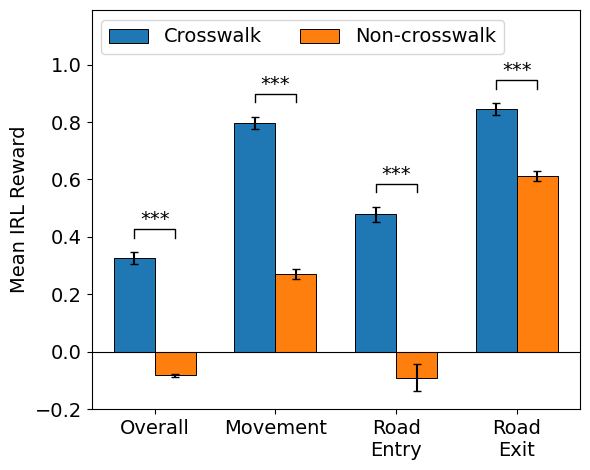

In [102]:
def _p_to_stars(p_value):
    if p_value < 0.001:
        return "***"
    if p_value < 0.01:
        return "**"
    if p_value < 0.05:
        return "*"
    return "n.s."

def _add_significance_bracket(
    ax,
    x1,
    x2,
    y,
    height,
    label,
    fontsize = 11,
):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        linewidth=1.0,
        color="black",
        clip_on=False,
    )
    ax.text(
        (x1 + x2) / 2,
        y + height,
        label,
        ha="center",
        va="bottom",
        fontsize=fontsize,
    )

def compact_mean_irl_reward_plot(
    values,
    *,
    ylabel="Mean IRL Reward",
    label_fontsize = 16,
    tick_fontsize = 14,
    legend_fontsize = 13,
    star_fontsize = 14,
    fig_size_scale = 1,
):
    grouped = values.reshape(values.shape[0], 4, 2)

    category_labels = [
        "Overall",
        "Movement",
        "Road\nEntry",
        "Road\nExit",
    ]
    condition_labels = [
        "Crosswalk",
        "Non-crosswalk",
    ]

    means = np.nanmean(grouped, axis=0)

    valid_counts = np.sum(np.isfinite(grouped), axis=0)
    standard_deviations = np.nanstd(grouped, axis=0, ddof=1)

    # 95% CI
    standard_errors = standard_deviations / np.sqrt(valid_counts)
    errors = np.full_like(standard_errors, np.nan, dtype=float)
    valid_ci = valid_counts >= 2
    errors[valid_ci] = t.ppf(0.975, df=valid_counts[valid_ci] - 1) * standard_errors[valid_ci]

    x = np.arange(len(category_labels))
    bar_width = 0.34
    offsets = np.array([-bar_width / 2, bar_width / 2])

    fig, ax = plt.subplots(figsize=(5*fig_size_scale, 4*fig_size_scale))

    for condition_idx, condition_label in enumerate(condition_labels):
        ax.bar(
            x + offsets[condition_idx],
            means[:, condition_idx],
            width=bar_width,
            yerr=errors[:, condition_idx],
            capsize=3,
            label=condition_label,
            edgecolor="black",
            linewidth=0.7,
        )


    test_results = []

    for category_idx in range(4):
        crosswalk_values = grouped[:, category_idx, 0]
        non_crosswalk_values = grouped[:, category_idx, 1]

        valid = (
            np.isfinite(crosswalk_values)
            & np.isfinite(non_crosswalk_values)
        )

        crosswalk_valid = crosswalk_values[valid]
        non_crosswalk_valid = non_crosswalk_values[valid]
        n = valid.sum()

        if n < 2:
            result = {
                "category": category_labels[category_idx].replace("\n", " "),
                "n": n,
                "df": np.nan,
                "t": np.nan,
                "p_raw": np.nan,
                "p_holm": np.nan,
                "mean_difference": np.nan,
                "dz": np.nan,
            }
        else:
            test = ttest_rel(
                crosswalk_valid,
                non_crosswalk_valid,
            )

            differences = crosswalk_valid - non_crosswalk_valid
            mean_difference = np.mean(differences)
            sd_difference = np.std(differences, ddof=1)

            dz = (
                mean_difference / sd_difference
                if sd_difference > 0
                else np.nan
            )

            result = {
                "category": category_labels[category_idx].replace("\n", " "),
                "n": n,
                "df": n - 1,
                "t": test.statistic,
                "p_raw": test.pvalue,
                "p_holm": np.nan,
                "mean_difference": mean_difference,
                "dz": dz,
            }

        test_results.append(result)

    raw_p_values = np.array(
        [result["p_raw"] for result in test_results],
        dtype=float,
    )

    valid_p_values = np.isfinite(raw_p_values)
    corrected_p_values = np.full_like(
        raw_p_values,
        np.nan,
        dtype=float,
    )

    if valid_p_values.any():
        corrected_p_values[valid_p_values] = multipletests(
            raw_p_values[valid_p_values],
            alpha=0.05,
            method="holm",
        )[1]

    for result, corrected_p in zip(
        test_results,
        corrected_p_values,
    ):
        result["p_holm"] = corrected_p

    finite_values = grouped[np.isfinite(grouped)]
    data_min = finite_values.min()
    data_max = finite_values.max()

    bracket_height = 0.03
    bracket_gap = 0.05

    highest_bracket = data_max

    for category_idx, result in enumerate(test_results):
        p_value = result["p_holm"]

        local_top = np.nanmax(means[category_idx] + errors[category_idx])
        bracket_y = local_top + bracket_gap

        label = "n.s." if np.isnan(p_value) else _p_to_stars(p_value)
        _add_significance_bracket(ax, x[category_idx] + offsets[0], x[category_idx] + offsets[1], bracket_y, bracket_height, label, fontsize=star_fontsize,)

        highest_bracket = max(highest_bracket, bracket_y + bracket_height)

    ax.set_xticks(x)
    ax.set_xticklabels(category_labels, fontsize=tick_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)
    ax.tick_params(axis="y", labelsize=tick_fontsize)

    ax.legend(
        ncol=2,
        loc="upper left",
        fontsize=legend_fontsize,
        frameon=True,
    )

    ax.set_ylim(-0.2, 1.19)
    ax.axhline(0, linewidth=0.8, color="black")

    fig.tight_layout()

    print("Paired comparisons: Crosswalk vs. Non-crosswalk")
    for result in test_results:
        raw_p_text = "< .001" if result["p_raw"] < 0.001 else f"= {result['p_raw']:.3f}"
        holm_p_text = "< .001" if result["p_holm"] < 0.001 else f"= {result['p_holm']:.3f}"
        print(
            f"{result['category']}: "
            f"t({result['df']}) = {result['t']:.2f}, "
            f"p {raw_p_text}, "
            f"Holm-corrected p {holm_p_text}, "
            f"dz = {result['dz']:.2f}, "
            f"mean difference = {result['mean_difference']:.3f}, "
            f"N = {result['n']}"
        )
    return fig, ax, test_results

fig, ax, test_results = compact_mean_irl_reward_plot(
    values=values,
    ylabel="Mean IRL Reward",
    label_fontsize=14,
    tick_fontsize=14,
    legend_fontsize=14,
    star_fontsize=14,
    fig_size_scale=1.2,
)

### Car Density Preference

In [103]:
web = None
subjIds = full_subjIds
reward_list_df = build_irl_reward_list(
    subjIds = subjIds,
    feat1_conds_list = [
        [car_density_cond(0)],
        [car_density_cond(1)],
        [car_density_cond(2)],
        [car_density_cond(3)],
        [car_density_cond(4)],
        [car_density_cond(5)],
        [car_density_cond(6)],
    ],
    feat2_conds_list = [
        [short_road_condition],
        [long_road_condition],
    ]
)

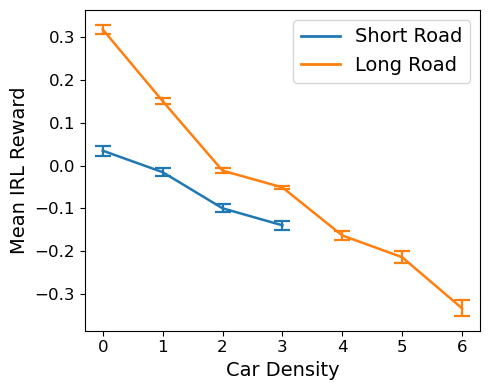

In [107]:
def mean_and_95ci(groups):
    means = []
    ci_half_widths = []
    ns = []

    for group in groups:
        values = np.asarray(group, dtype=float)
        values = values[np.isfinite(values)]

        n = len(values)
        mean = np.mean(values)

        sd = np.std(values, ddof=1)
        sem = sd / np.sqrt(n)
        ci = stats.t.ppf(0.975, df=n - 1) * sem

        means.append(mean)
        ci_half_widths.append(ci)
        ns.append(n)

    return (
        np.asarray(means),
        np.asarray(ci_half_widths),
        np.asarray(ns),
    )


short_groups = reward_list_df[0]
long_groups = reward_list_df[1]

import warnings

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=RuntimeWarning)
    short_means, short_ci, short_ns = mean_and_95ci(short_groups)
    long_means, long_ci, long_ns = mean_and_95ci(long_groups)

fig, ax = plt.subplots(figsize=(5, 4))

x_short = np.arange(len(short_means))
ax.errorbar(
    x_short,
    short_means,
    yerr=short_ci,
    fmt="-",
    # marker="o",
    # markersize=5,
    linewidth=1.8,
    elinewidth=1.6,
    capsize=6,
    capthick=1.6,
    zorder=3,
    label="_nolegend_",
)

x_long = np.arange(len(long_means))
ax.errorbar(
    x_long,
    long_means,
    yerr=long_ci,
    fmt="-",
    # marker="o",
    # markersize=5,
    linewidth=1.8,
    elinewidth=1.6,
    capsize=6,
    capthick=1.6,
    zorder=3,
    label="_nolegend_",
)

legend_handles = [
    Line2D([0], [0], color="tab:blue", linewidth=2, label="Short Road"),
    Line2D([0], [0], color="tab:orange", linewidth=2, label="Long Road"),
]

ax.set_xlabel("Car Density", fontsize=14)
ax.set_ylabel("Mean IRL Reward", fontsize=14)
ax.set_xticks(np.arange(max(len(x_short), len(x_long))))
ax.tick_params(axis="both", labelsize=12)
ax.legend(handles=legend_handles, fontsize=14)

fig.tight_layout()

### Time Left Plot

In [105]:
def calculate_mean_and_95ci(groups):
    means = []
    ci_lower = []
    ci_upper = []
    ns = []

    for group in groups:
        values = np.asarray(group, dtype=float)
        values = values[np.isfinite(values)]

        n = len(values)
        ns.append(n)

        if n == 0:
            means.append(np.nan)
            ci_lower.append(np.nan)
            ci_upper.append(np.nan)
            continue

        mean = np.mean(values)
        means.append(mean)

        if n < 2:
            ci_lower.append(np.nan)
            ci_upper.append(np.nan)
            continue

        sd = np.std(values, ddof=1)
        sem = sd / np.sqrt(n)
        critical_value = t.ppf(0.975, df=n - 1)
        ci_half_width = critical_value * sem

        ci_lower.append(mean - ci_half_width)
        ci_upper.append(mean + ci_half_width)

    return (
        np.asarray(means),
        np.asarray(ci_lower),
        np.asarray(ci_upper),
        np.asarray(ns),
    )

bin_count = 30
feat2_reward_condition_list = None

subjIds = full_subjIds
time_conditions = time_left_cond_bins(bin_count)

# feat2 condition × time bin × participant
overall_reward_list = build_irl_reward_list(
    subjIds=subjIds,
    feat1_conds_list=time_conditions,
    feat2_conds_list=[[always_true_cond]],
    feat2_reward_condition_list=feat2_reward_condition_list,
)

# Finish line not visible
finish_line_reward_list = build_irl_reward_list(
    subjIds=subjIds,
    feat1_conds_list=time_conditions,
    feat2_conds_list=[[finish_line_not_visible_cond]],
    feat2_reward_condition_list=feat2_reward_condition_list,
)

overall_groups = overall_reward_list[0]
finish_line_groups = finish_line_reward_list[0]

(
    overall_means,
    overall_ci_lower,
    overall_ci_upper,
    overall_ns,
) = calculate_mean_and_95ci(overall_groups)

(
    finish_line_means,
    finish_line_ci_lower,
    finish_line_ci_upper,
    finish_line_ns,
) = calculate_mean_and_95ci(finish_line_groups)

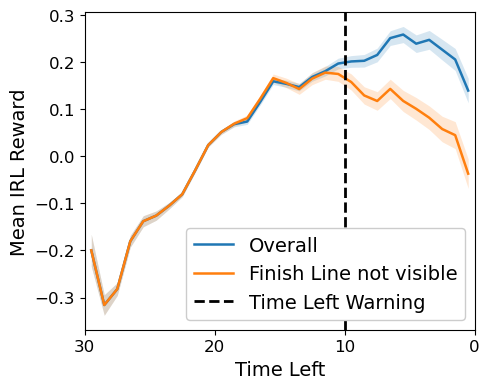

In [106]:
bin_centers = np.linspace(
    0.5 / bin_count,
    (bin_count - 0.5) / bin_count,
    bin_count,
)

fig, ax = plt.subplots(figsize=(5, 4))

# Overall
overall_line, = ax.plot(
    bin_centers,
    overall_means,
    linewidth=1.8,
    label="Overall",
)

ax.fill_between(
    bin_centers,
    overall_ci_lower,
    overall_ci_upper,
    color=overall_line.get_color(),
    alpha=0.18,
    linewidth=0,
)

# Finish line not visible
finish_line_line, = ax.plot(
    bin_centers,
    finish_line_means,
    linewidth=1.8,
    label="Finish Line not visible",
)

ax.fill_between(
    bin_centers,
    finish_line_ci_lower,
    finish_line_ci_upper,
    color=finish_line_line.get_color(),
    alpha=0.18,
    linewidth=0,
)

# 10 seconds left warning
ax.axvline(
    x=20 / 30,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Time Left Warning",
)

xtick_length = 4
xticks = np.linspace(0, 1, xtick_length)
xtick_labels = np.linspace(30, 0, xtick_length)

ax.set_xticks(xticks)
ax.set_xticklabels(
    [f"{value:.0f}" for value in xtick_labels],
    fontsize=12,
)

ax.set_xlim(0, 1)
ax.tick_params(axis="y", labelsize=12)
ax.set_xlabel("Time Left", fontsize=14)
ax.set_ylabel("Mean IRL Reward", fontsize=14)
ax.legend(fontsize=14, framealpha=1.0)

# ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Risk Preference Indicator Selection

### [1] Safest Road Crossing (r=-0.226***)

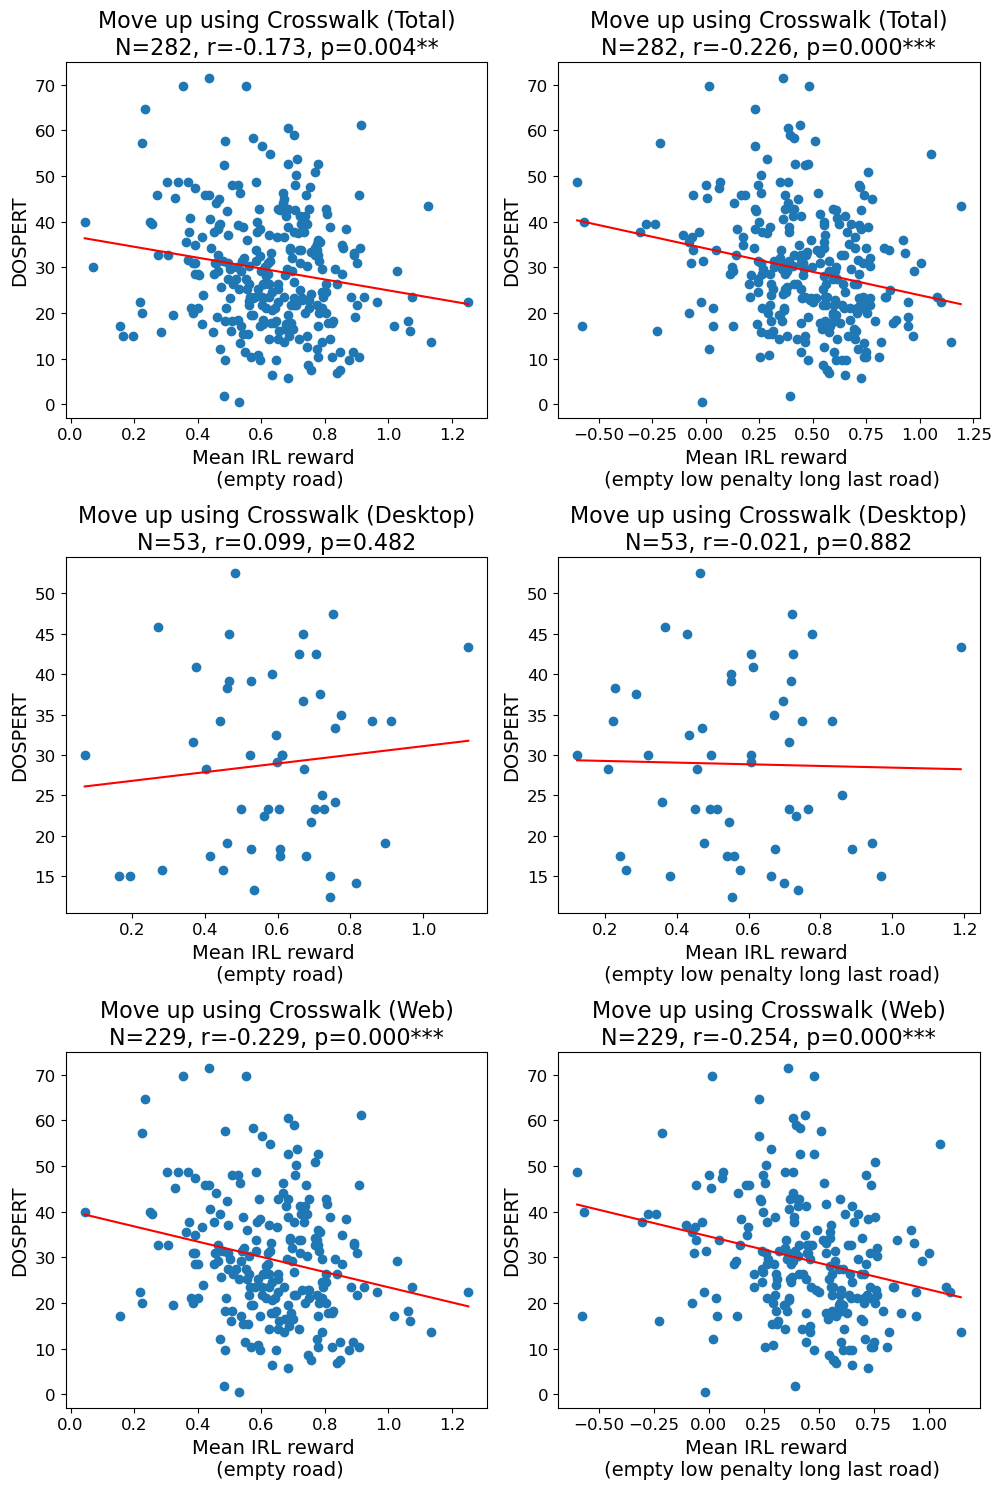

In [85]:
conds1=[
    [always_true_cond, car_density_cond(0), inside_crosswalk_cond, move_up],
    [always_true_cond, car_density_cond(0), inside_crosswalk_cond, last_road_condition, long_road_condition, low_penalty_road_cond, move_up],
]
conds2=[
    [always_true_cond],
]
rows = ['full', 'desktop', 'web']
fig, axes = plt.subplots(len(rows), len(conds1), figsize=(5 * len(conds1), 5 * len(rows)))
for i in range(len(conds1)):
    xlabel = [
        "Mean IRL reward \n (empty road)",
        "Mean IRL reward \n (empty low penalty long last road)",
    ][i]
    for j in range(len(rows)):
        subjIds = [full_subjIds, desktop_subjIds, web_subjIds][j] 
        title = [
            "Move up using Crosswalk (Total)",
            "Move up using Crosswalk (Desktop)",
            "Move up using Crosswalk (Web)",
        ][j]
        irl_mean_diff_cor_plot(
            # axes,
            axes[i] if len(rows) == 1 else axes[j, i],
            title,
            xlabel,
            subjIds,
            feat1_conds_list=[conds1[i]],
            feat2_conds_list = [conds2[0]],
            feat2_reward_condition_list = None,
            questionnaire="DOSPERT"
        )
plt.tight_layout()
plt.show()

### [2] Waiting in Crosswalk for Car to Pass (r=-0.226***)

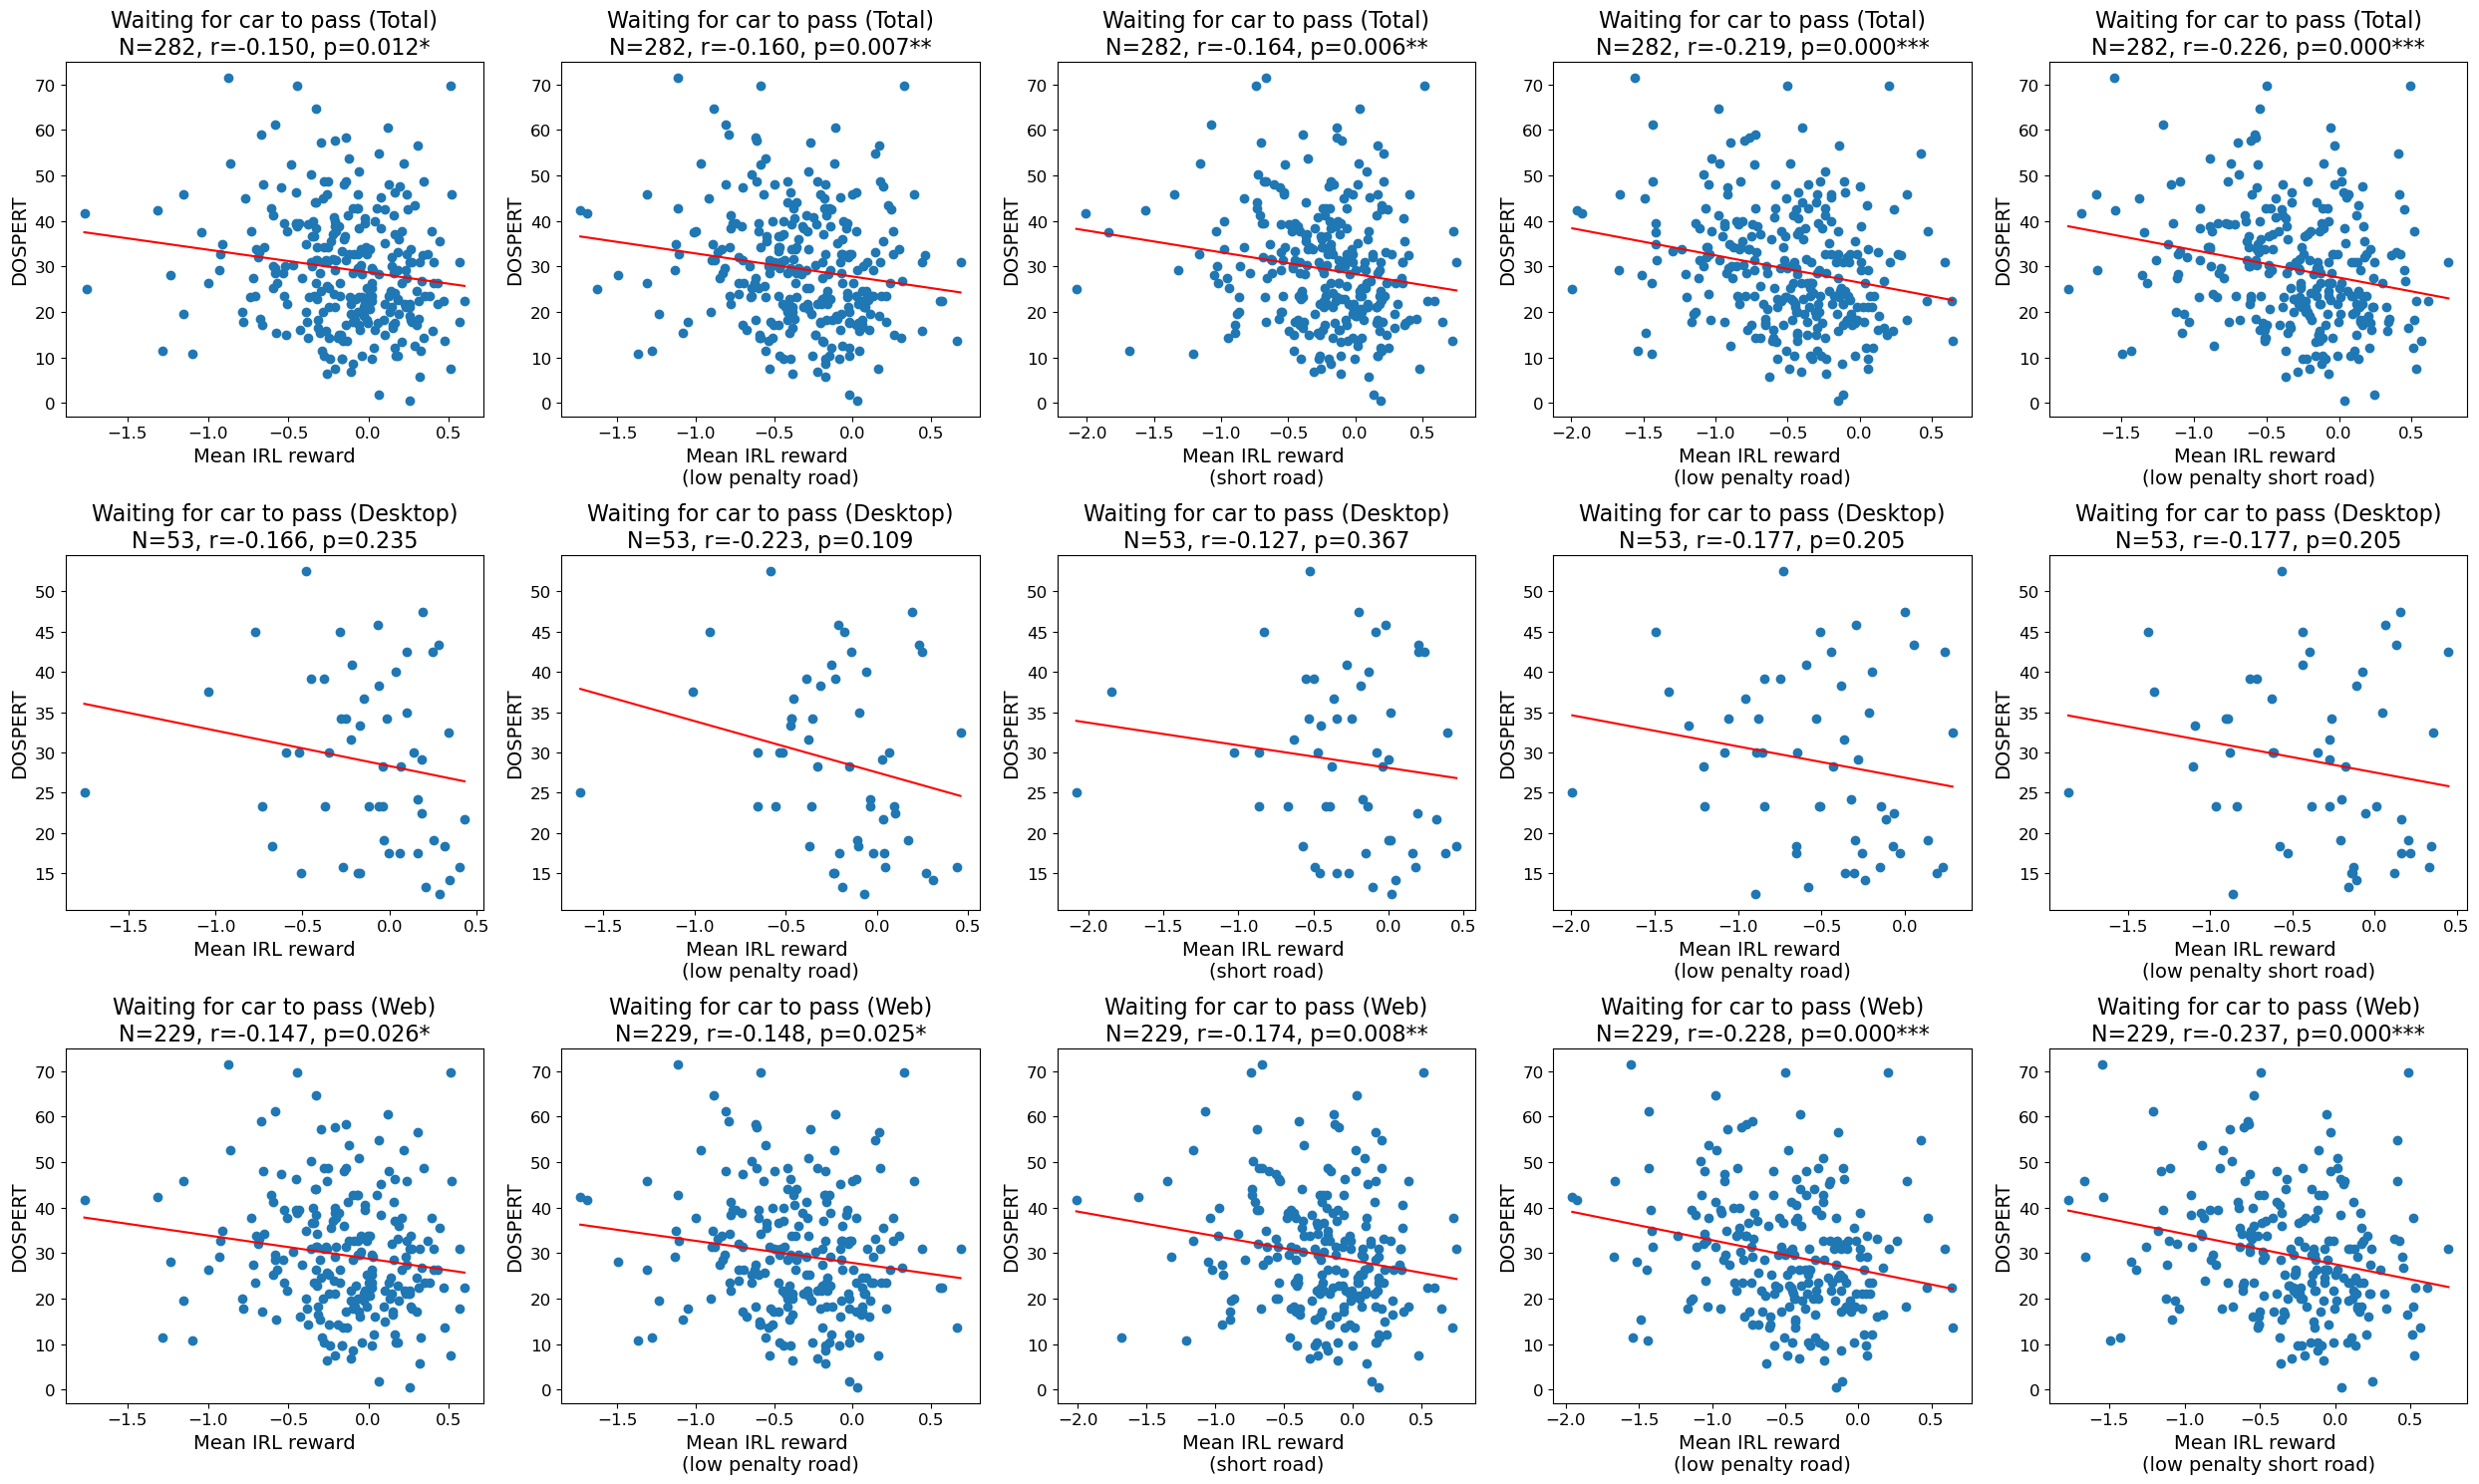

In [86]:
conds1=[
    [always_true_cond, car_in_front_N_cond, inside_crosswalk_cond, last_road_condition, no_op],
    [always_true_cond, car_in_front_N_cond, inside_crosswalk_cond, last_road_condition, low_penalty_road_cond, no_op],
    [always_true_cond, car_in_front_N_cond, inside_crosswalk_cond, last_road_condition, no_op, short_road_condition],
    [always_true_cond, car_in_front_N_cond, inside_crosswalk_cond, last_road_condition, low_penalty_road_cond, no_op, short_road_condition],
    [always_true_cond, car_in_front_N_cond, inside_crosswalk_cond, last_road_condition, low_penalty_road_cond, no_op, safe_zone_cond, short_road_condition],
]
conds2=[
    [always_true_cond],
]
rows = ['full', 'desktop', 'web']
fig, axes = plt.subplots(len(rows), len(conds1), figsize=(5 * len(conds1), 5 * len(rows)))
for i in range(len(conds1)):
    xlabel = [
        "Mean IRL reward",
        "Mean IRL reward \n(low penalty road)",
        "Mean IRL reward \n(short road)",
        "Mean IRL reward \n(low penalty road)",
        "Mean IRL reward \n(low penalty short road)",
        "Mean IRL reward \n(safe zone \n +low penalty short road)",
    ][i]
    for j in range(len(rows)):
        subjIds = [full_subjIds, desktop_subjIds, web_subjIds][j] 
        title = [
            "Waiting for car to pass (Total)",
            "Waiting for car to pass (Desktop)",
            "Waiting for car to pass (Web)",
        ][j]
        irl_mean_diff_cor_plot(
            # axes,
            axes[i] if len(rows) == 1 else axes[j, i],
            title,
            xlabel,
            subjIds,
            feat1_conds_list=[conds1[i]],
            # feat1_diff_conds_list=[diff_conds1[0]],
            feat2_conds_list = [conds2[0]],
            feat2_reward_condition_list = None,
            questionnaire="DOSPERT"
        )
plt.tight_layout()
plt.show()

#### Car closeness tuning

In [87]:
wait_df1_v1, wait_df2_v1 = build_custom_mean_irl_heatmap_dfs(
    subjIds=full_subjIds,
    common_cond = [always_true_cond, inside_crosswalk_cond, last_road_condition, low_penalty_road_cond, no_op, safe_zone_cond], #, short_road_condition],
    conds_map = [
        encoming_car_in_front4_thresh_bins(5, full=True),
        encoming_car_in_front3_thresh_bins(5, full=True),
        encoming_car_in_front2_thresh_bins(5, full=True),
        encoming_car_in_front1_thresh_bins(5, full=True),
    ],
    verbose=False,
    questionnaire="DOSPERT",
)

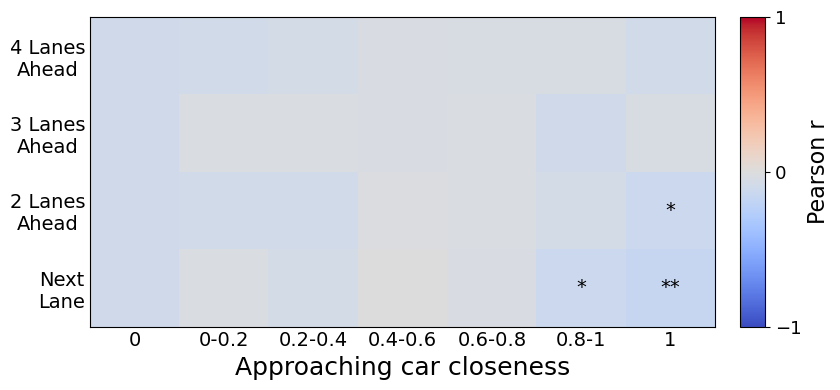

In [88]:
feat1_label = "Approaching car closeness" # \n(0 = no car in sight; 1 = directly in front)"
feat1_ticks = ["0", "0-0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8-1", "1"]

feat2_label = ""
feat2_ticks = ["4 Lanes\nAhead", "3 Lanes\nAhead", "2 Lanes\nAhead", "Next\nLane"] #, "Current\nLane"]

cor_title=""
main_font_size = 16

plot_irl_corr_heatmap_poster_figure(
    wait_df2_v1, feat1_label, feat2_label, feat1_ticks=feat1_ticks, feat2_ticks=feat2_ticks, 
    star_only=True, 
    cor_title=cor_title, main_font_size=main_font_size
)

### [3] High Risk but Empty Last Road (r=0.194**)

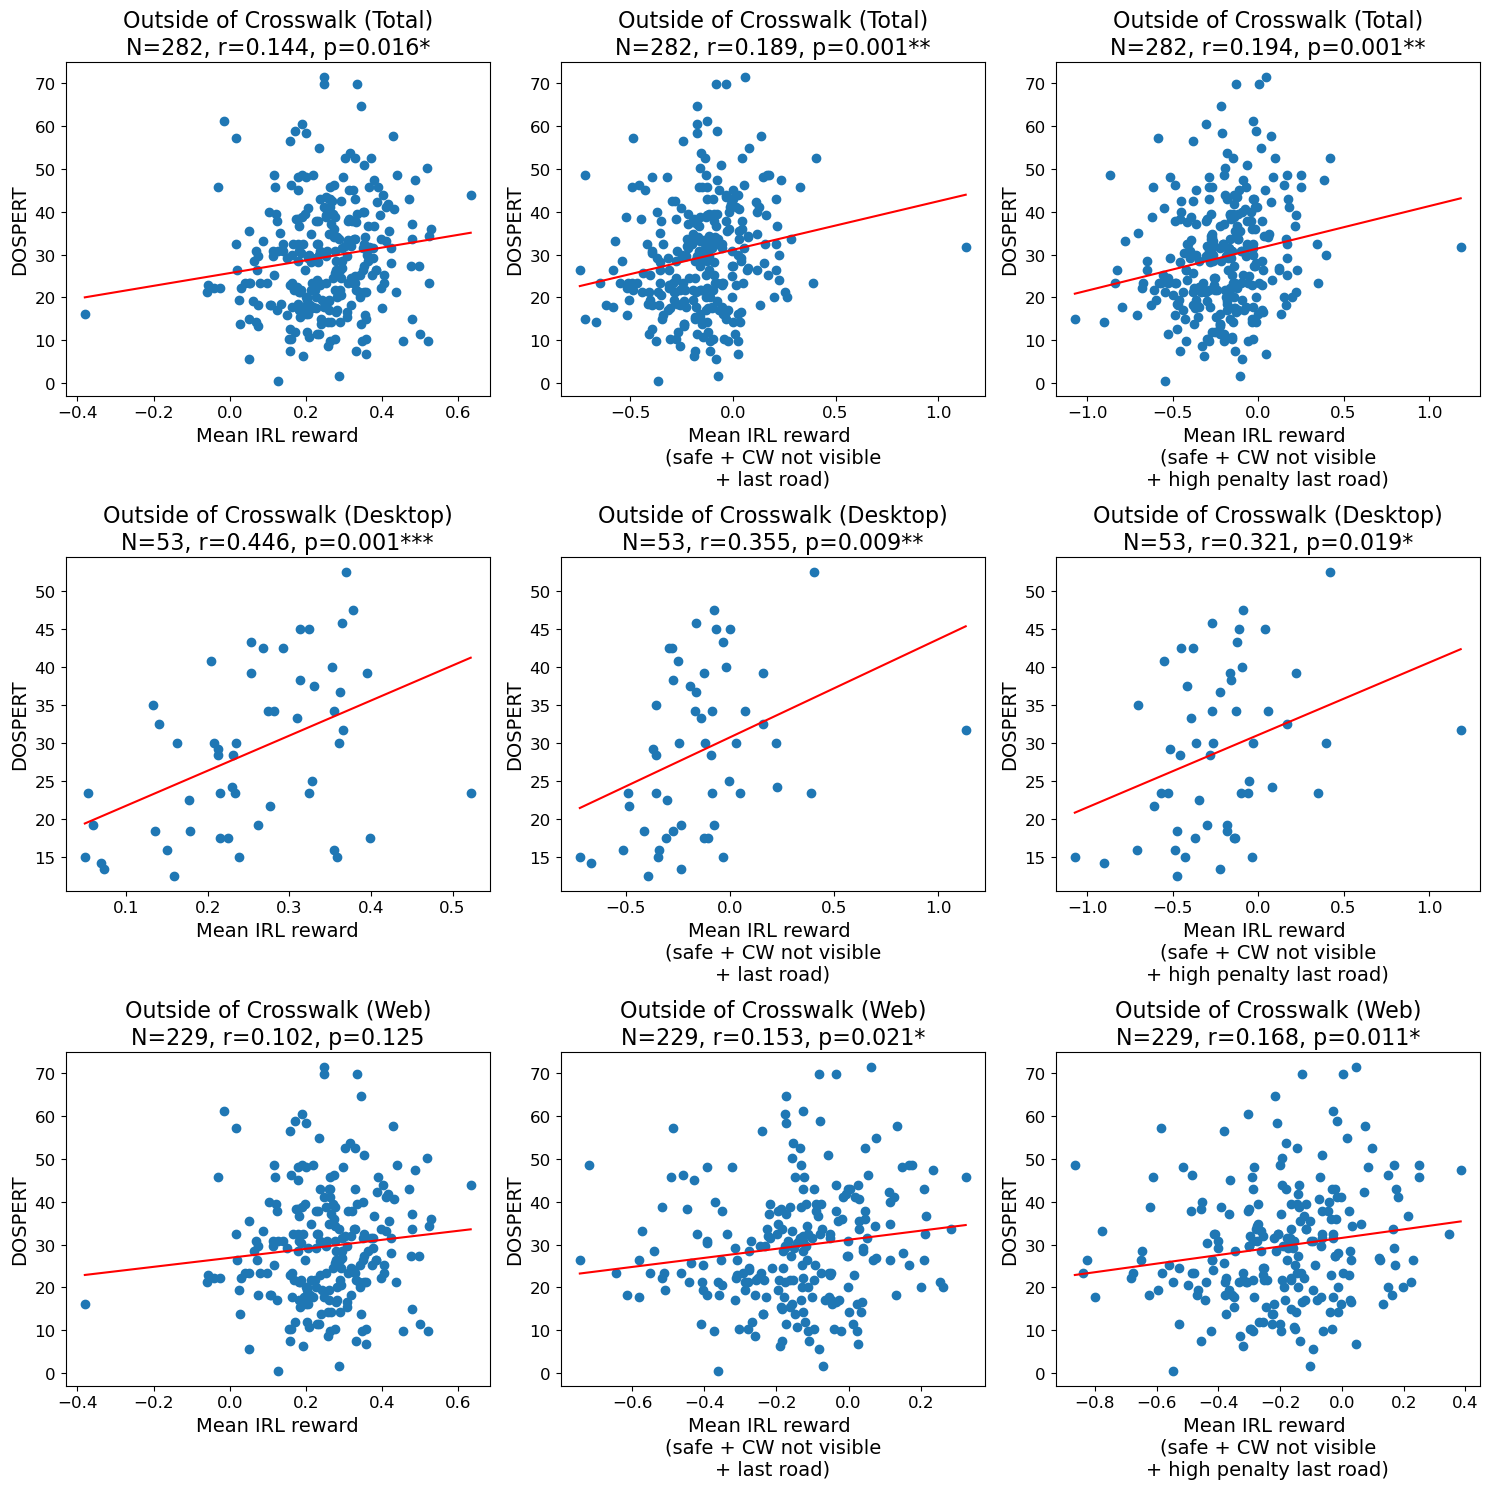

In [89]:
conds1=[
    [always_true_cond, car_density_cond(0), long_road_condition, outside_crosswalk_cond],
    [always_true_cond, car_density_cond(0), long_road_condition, outside_crosswalk_cond, crosswalk_not_visible_cond, last_road_condition, safe_zone_cond],
    [always_true_cond, car_density_cond(0), long_road_condition, outside_crosswalk_cond, crosswalk_not_visible_cond, last_road_condition, high_penalty_road_cond, safe_zone_cond],
]
conds2=[
    [always_true_cond]
]
fig, axes = plt.subplots(3, len(conds1), figsize=(5 * len(conds1), 5 * 3))
for i in range(len(conds1)):
    xlabel = [
        "Mean IRL reward",
        "Mean IRL reward \n(safe + CW not visible\n+ last road)",
        "Mean IRL reward \n(safe + CW not visible\n+ high penalty last road)",
    ][i]
    for j in range(3):
        subjIds = [full_subjIds, desktop_subjIds, web_subjIds][j] 
        title = [
            "Outside of Crosswalk (Total)",
            "Outside of Crosswalk (Desktop)",
            "Outside of Crosswalk (Web)",
        ][j]
        irl_mean_diff_cor_plot(
            axes[j, i],
            title,
            xlabel,
            subjIds,
            feat1_conds_list=[conds1[i]],
            feat2_conds_list = [conds2[0]],
            feat2_reward_condition_list = None,
            questionnaire="DOSPERT"
        )
plt.tight_layout()
plt.show()

### [4] Approaching Crosswalk in Current Road (r=0.183**)

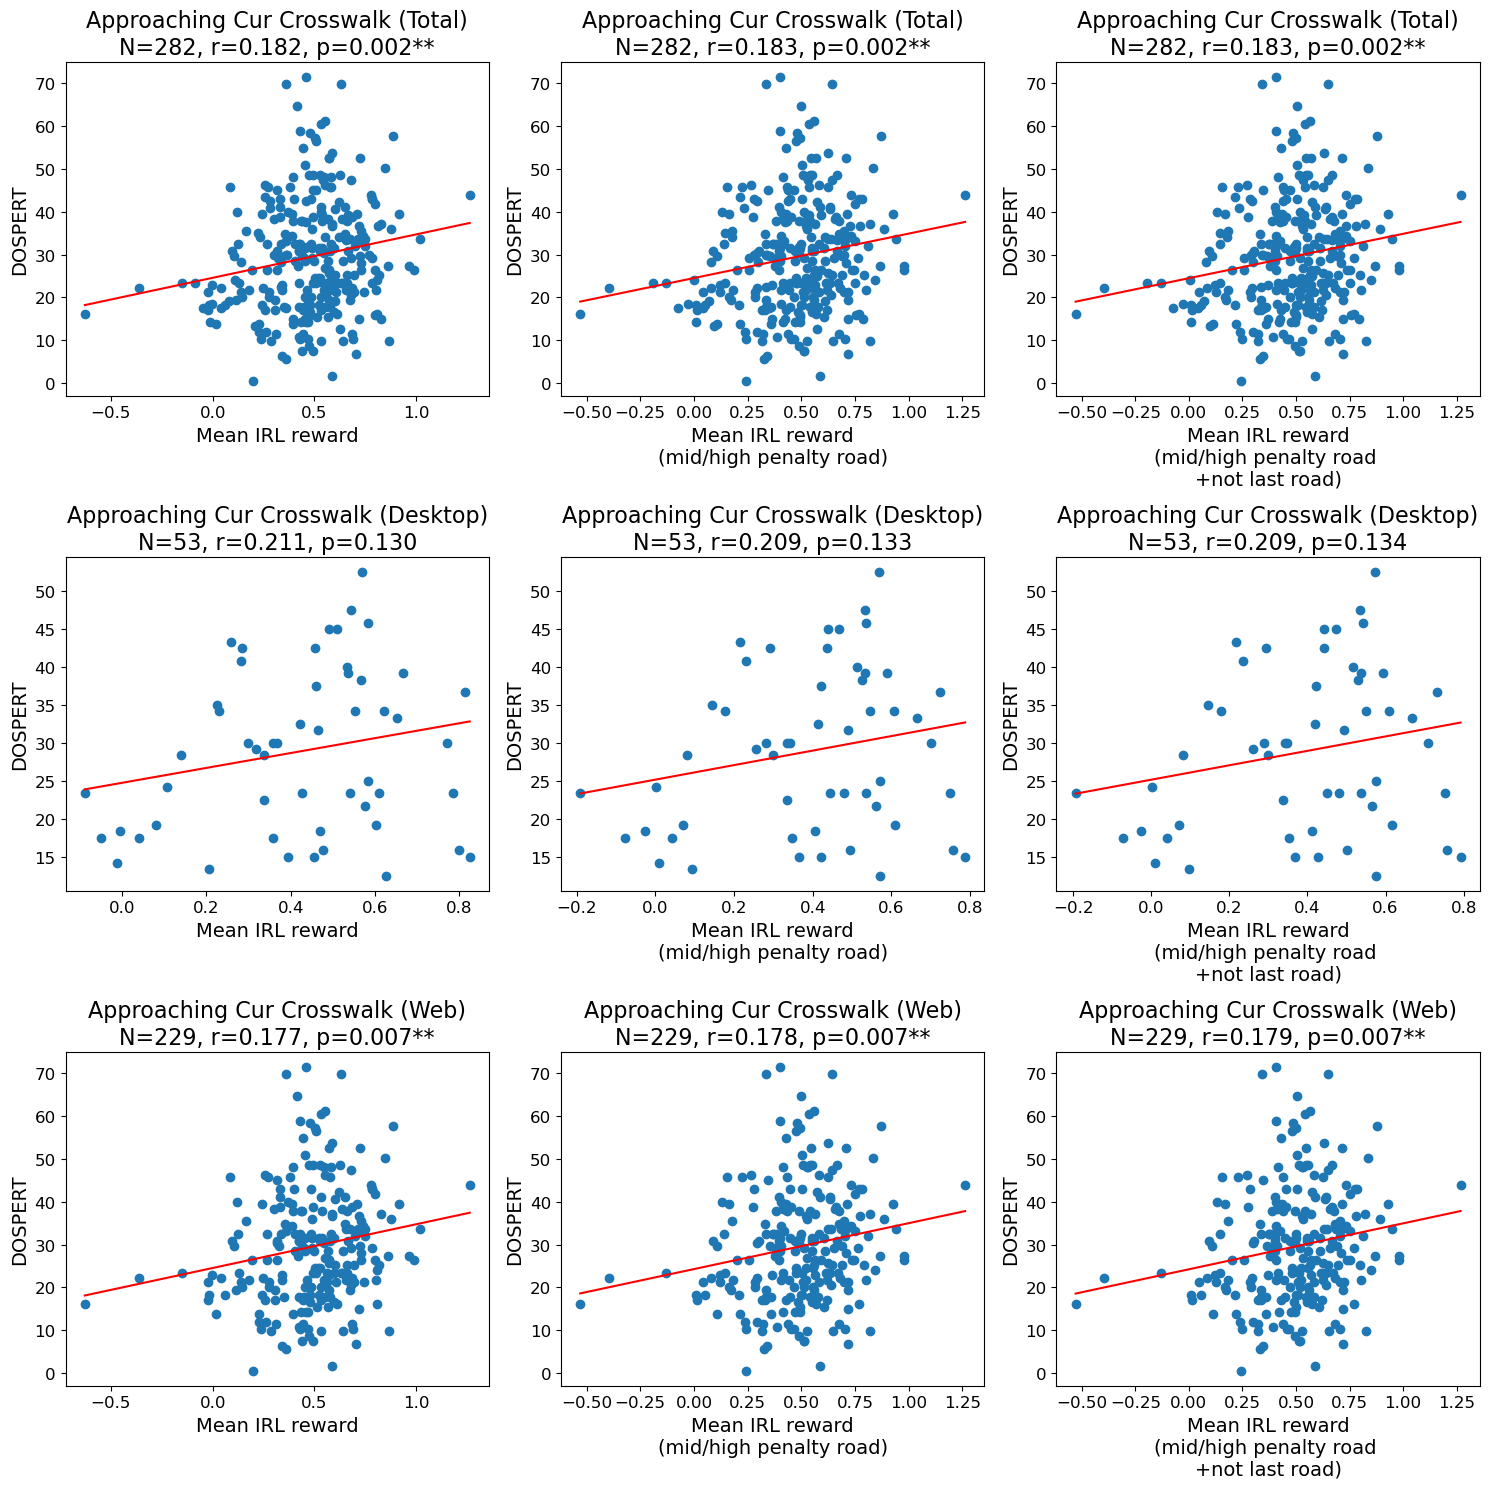

In [90]:
conds1=[
    [always_true_cond, car_density_cond(0), danger_zone_cond, long_road_condition, move_toward_crosswalk_depth1, outside_crosswalk_cond], # 0.18219
    [always_true_cond, car_density_cond(0), danger_zone_cond, long_road_condition, mid_or_high_penalty_road_cond, move_toward_crosswalk_depth1, outside_crosswalk_cond], # r=0.182580
    [always_true_cond, car_density_cond(0), danger_zone_cond, long_road_condition, mid_or_high_penalty_road_cond, move_toward_crosswalk_depth1, not_last_road_condition, outside_crosswalk_cond], # r=0.1829
]
conds2=[
    [always_true_cond],
]

fig, axes = plt.subplots(3, len(conds1), figsize=(5 * len(conds1), 5 * 3))
for i in range(len(conds1)):
    xlabel = [
        "Mean IRL reward",
        "Mean IRL reward\n(mid/high penalty road)",
        "Mean IRL reward\n(mid/high penalty road \n+not last road)",
    ][i]
    for j in range(3):
        subjIds = [full_subjIds, desktop_subjIds, web_subjIds][j] 
        title = [
            "Approaching Cur Crosswalk (Total)",
            "Approaching Cur Crosswalk (Desktop)",
            "Approaching Cur Crosswalk (Web)",
        ][j]
        irl_mean_diff_cor_plot(
            axes[j, i],
            title,
            xlabel,
            subjIds,
            feat1_conds_list=[conds1[i]],
            feat2_conds_list = [conds2[0]],
            feat2_reward_condition_list = None,
            questionnaire="DOSPERT"
        )
plt.tight_layout()
plt.show()

### [5] Approaching Next Crosswalks (r=0.200***)

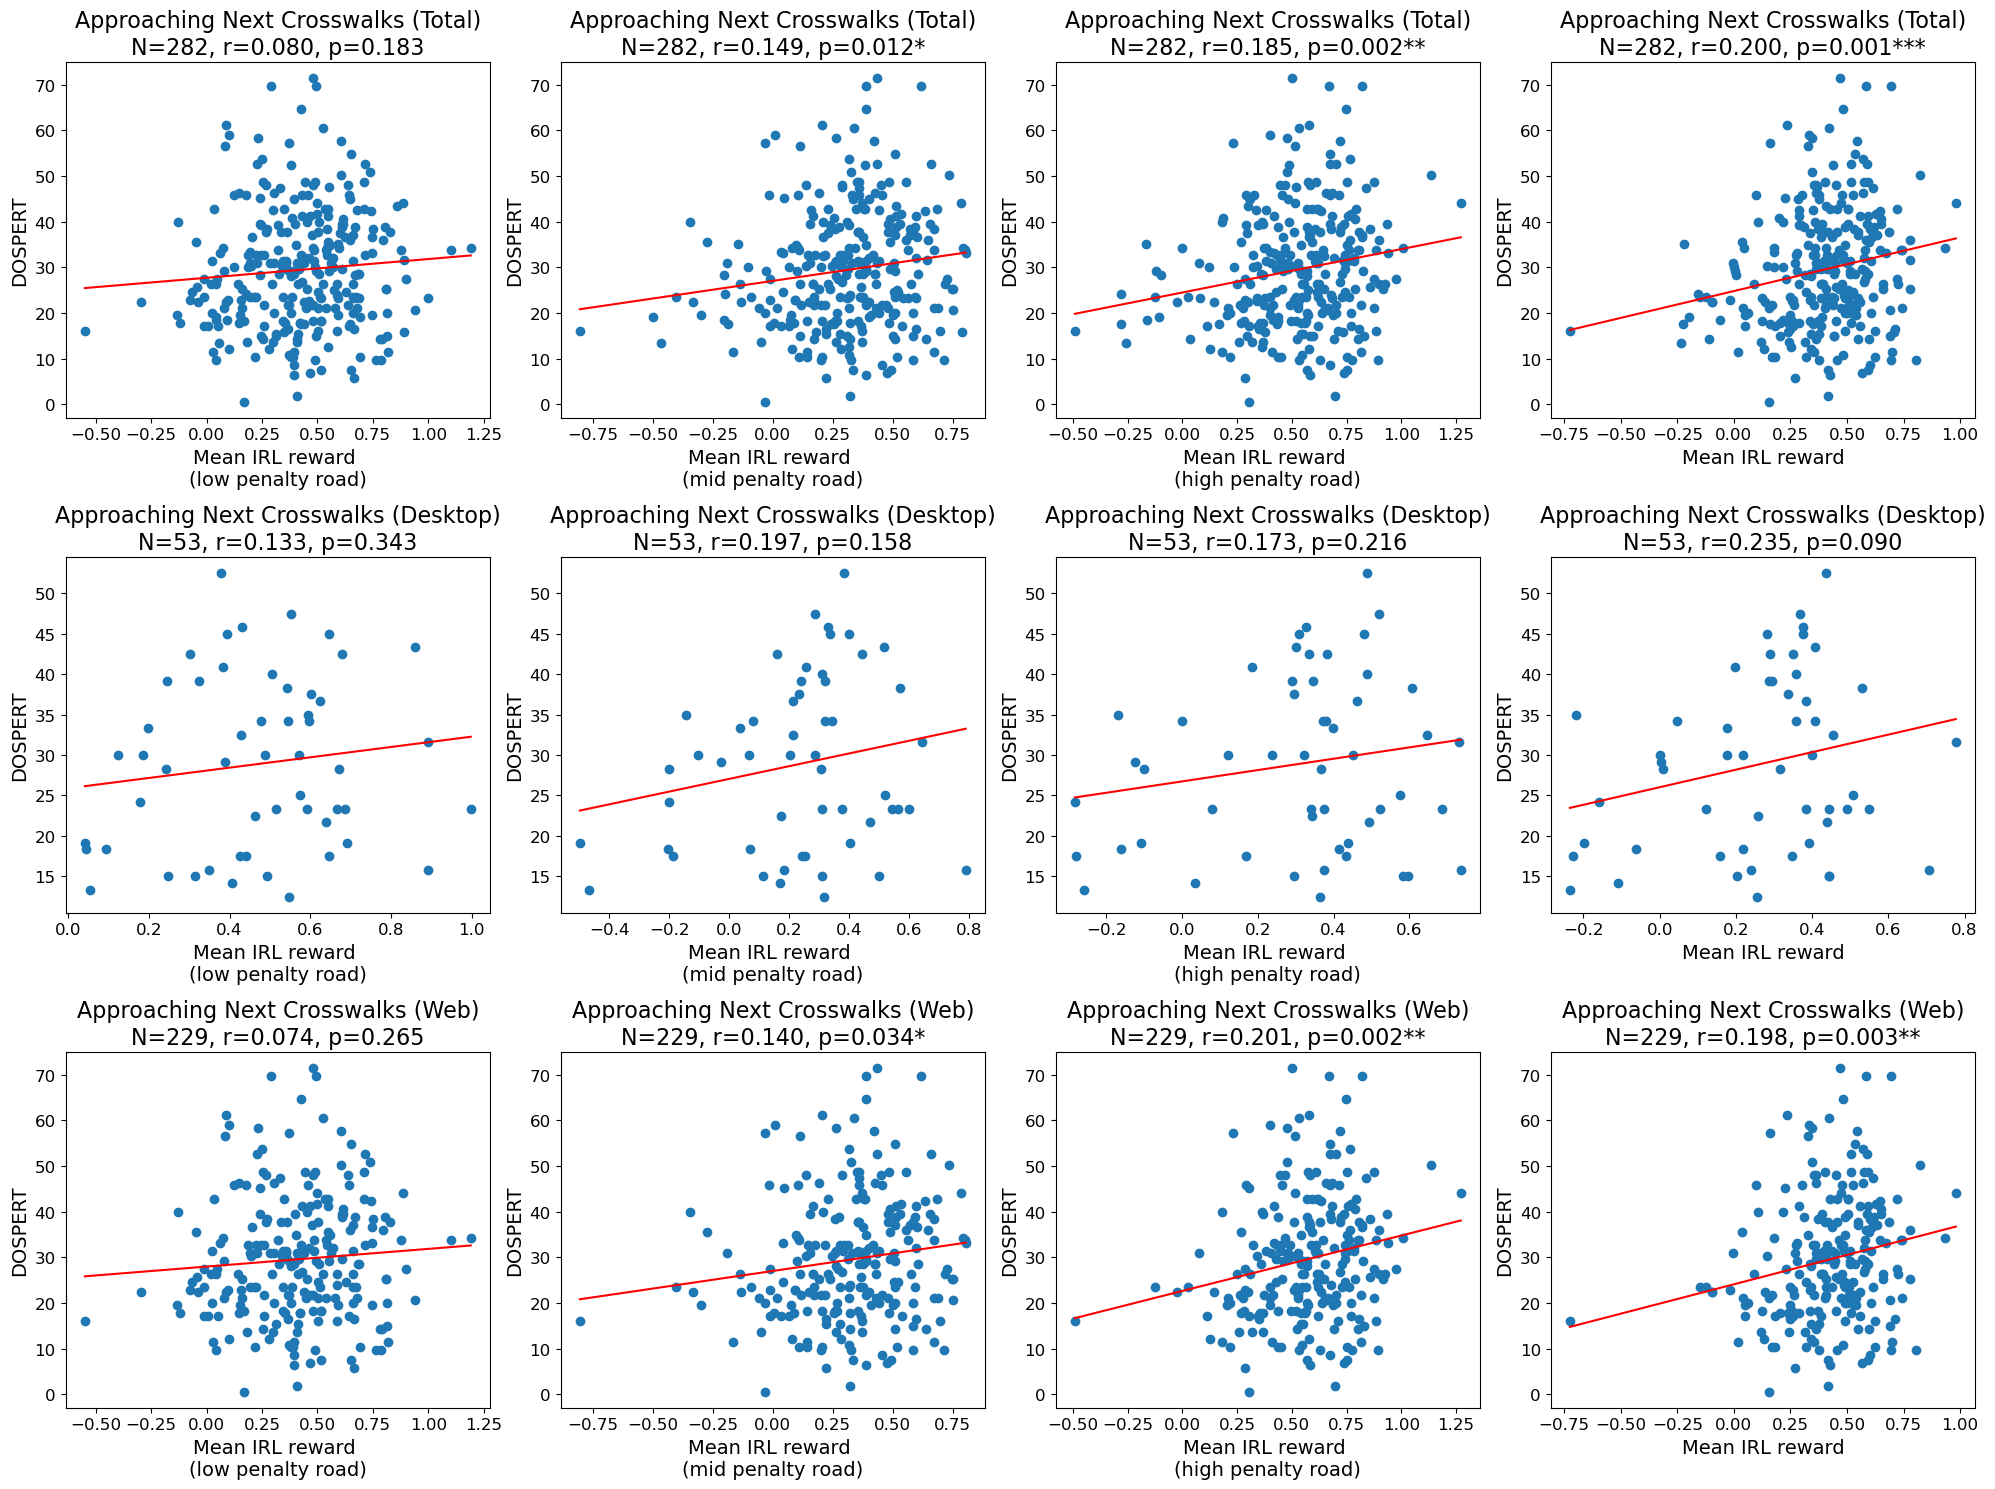

In [91]:
conds1=[
    [always_true_cond, car_density_cond(0), danger_zone_cond, long_road_condition, move_toward_next_crosswalks, outside_crosswalk_cond, low_penalty_road_cond],
    [always_true_cond, car_density_cond(0), danger_zone_cond, long_road_condition, move_toward_next_crosswalks, outside_crosswalk_cond, mid_penalty_road_cond],
    [always_true_cond, long_road_condition, move_toward_next_crosswalks, outside_crosswalk_cond, danger_zone_cond, car_density_cond(0), high_penalty_road_cond],
    [always_true_cond, car_density_cond(0), danger_zone_cond, long_road_condition, move_toward_next_crosswalks, outside_crosswalk_cond],
]
conds2=[
    [always_true_cond],
]

fig, axes = plt.subplots(3, len(conds1), figsize=(5 * len(conds1), 5 * 3))
for i in range(len(conds1)):
    xlabel = [
        "Mean IRL reward \n(low penalty road)",
        "Mean IRL reward \n(mid penalty road)",
        "Mean IRL reward \n(high penalty road)",
        "Mean IRL reward",
    ][i]
    for j in range(3):
        subjIds = [full_subjIds, desktop_subjIds, web_subjIds][j] 
        title = [
            "Approaching Next Crosswalks (Total)",
            "Approaching Next Crosswalks (Desktop)",
            "Approaching Next Crosswalks (Web)",
        ][j]
        irl_mean_diff_cor_plot(
            axes[j, i],
            title,
            xlabel,
            subjIds,
            feat1_conds_list=[conds1[i]],
            feat2_conds_list = [conds2[0]],
            feat2_reward_condition_list = None,
            questionnaire="DOSPERT"
        )
plt.tight_layout()
plt.show()

### [6] Move Up Toward Car (r=0.222**)

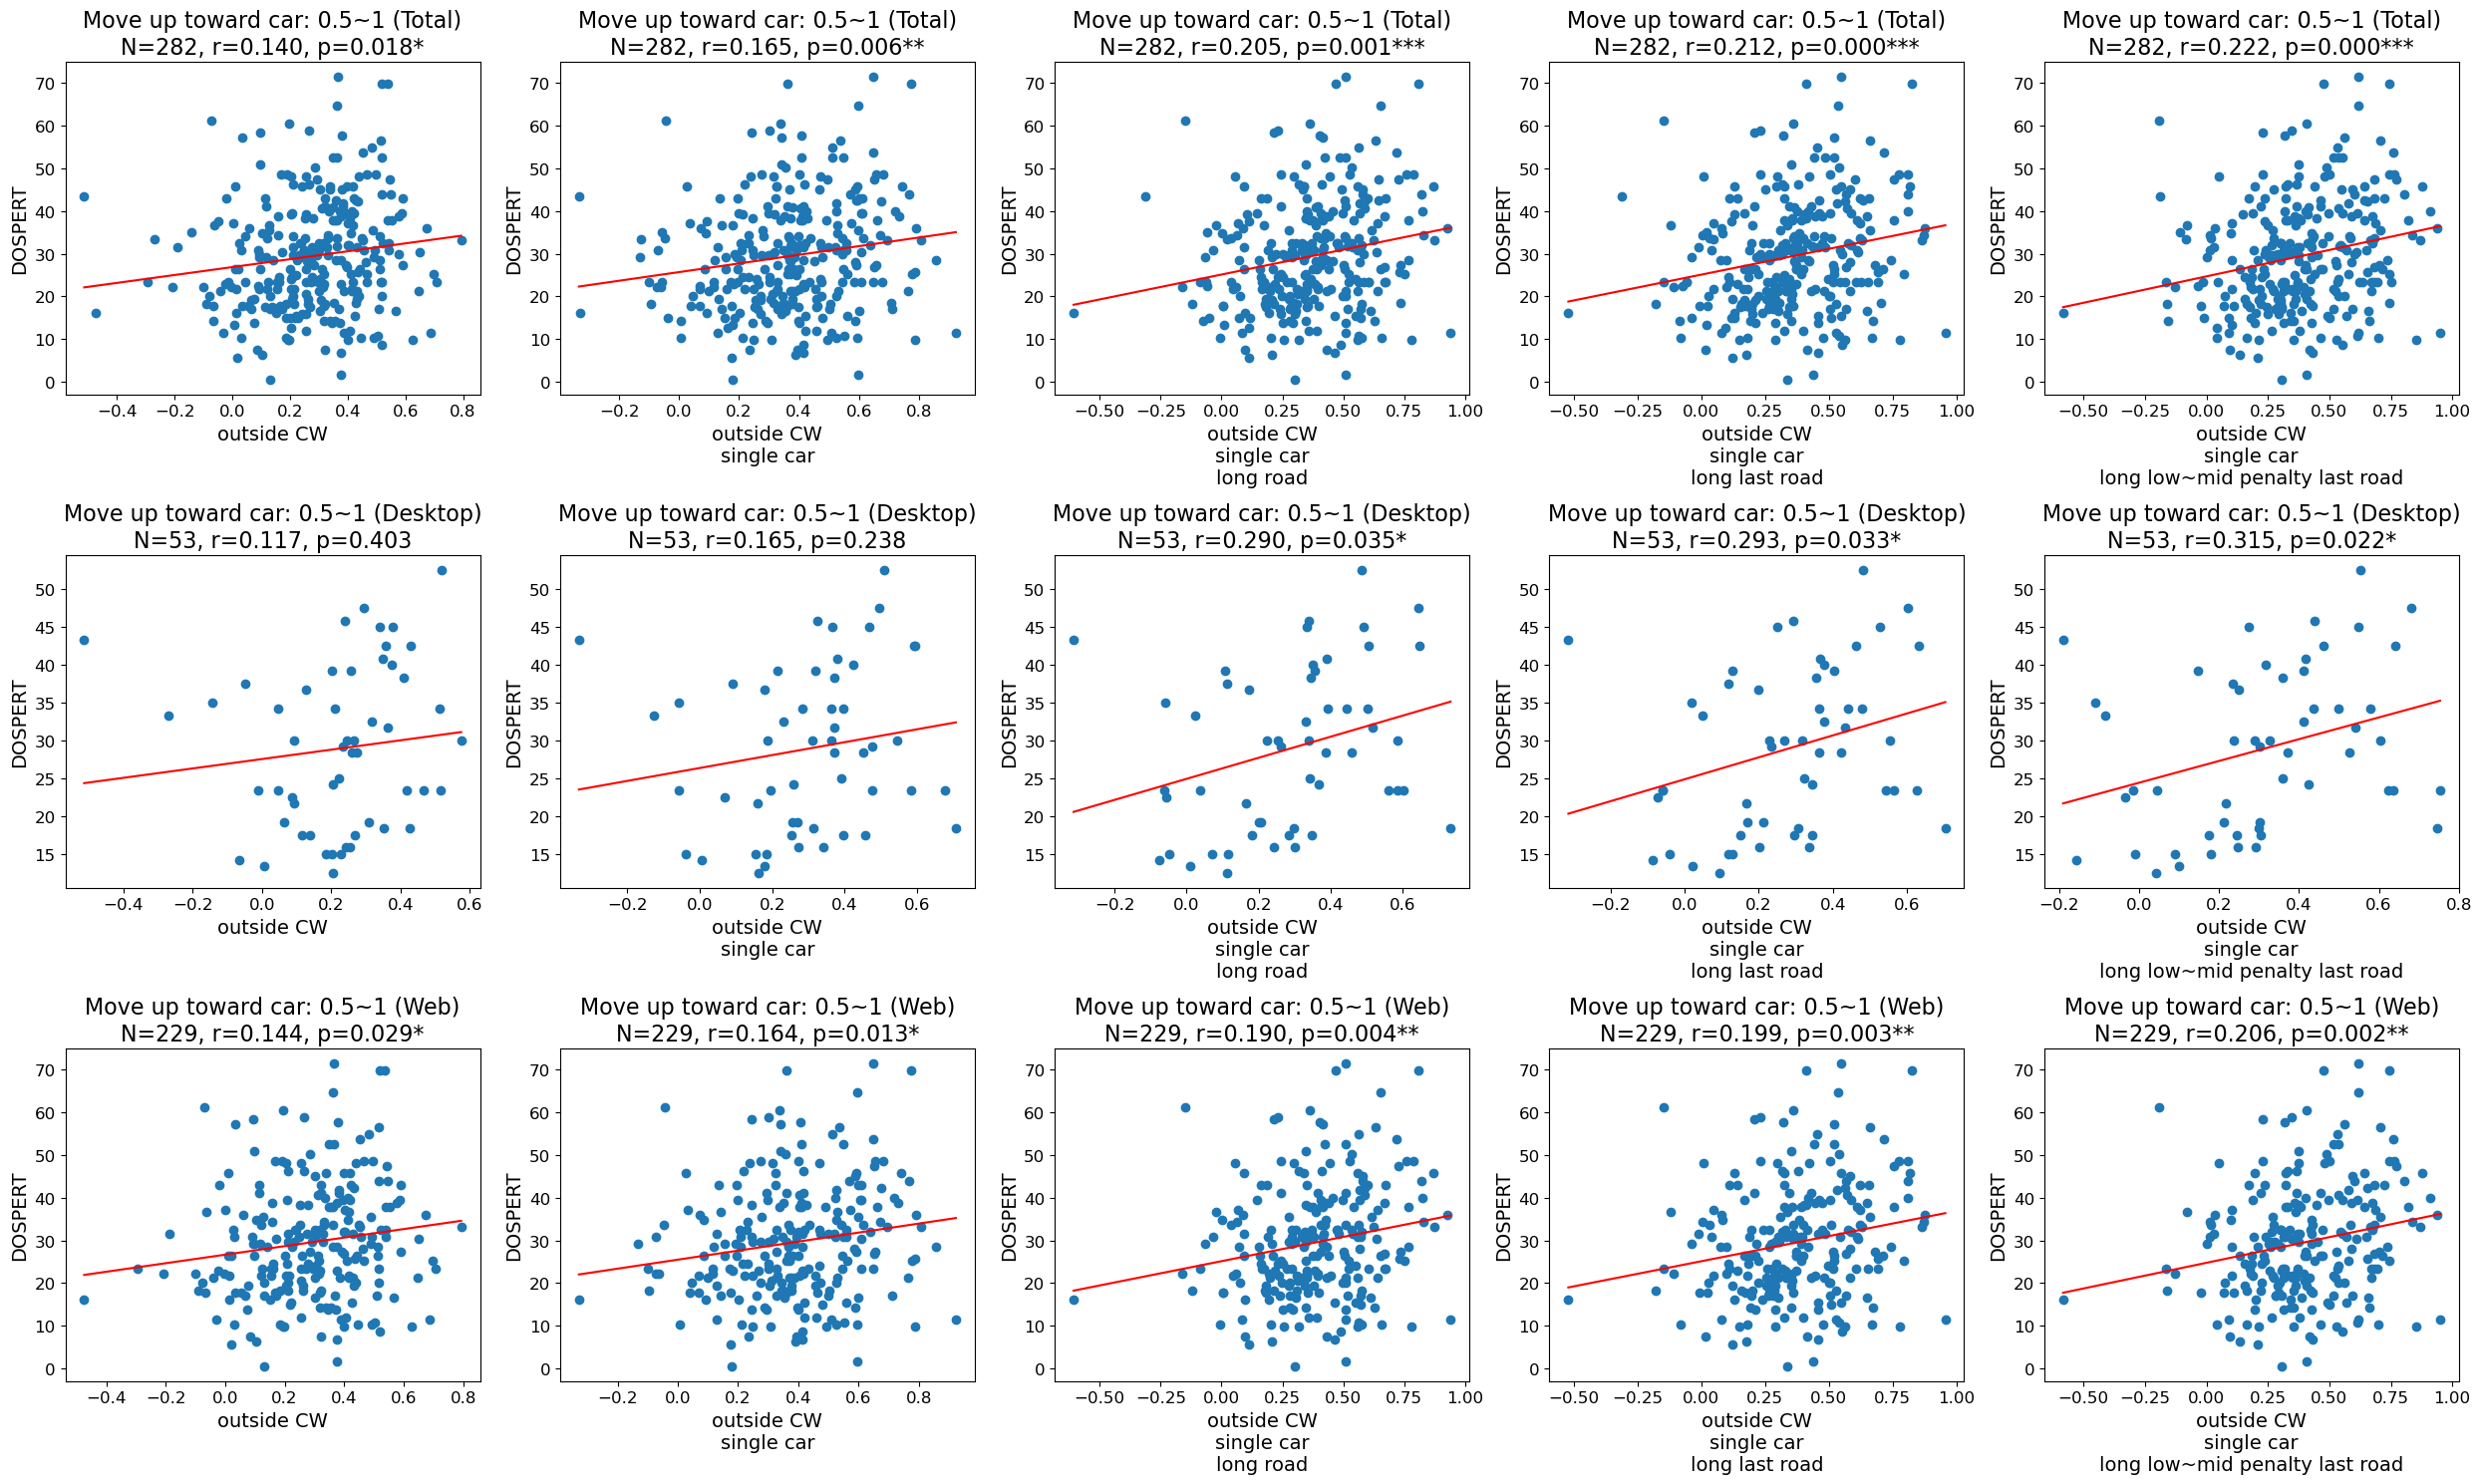

In [92]:
conds1=[
    [always_true_cond, encoming_car_in_front1_thresh((0.4, 0.6)), move_up, outside_crosswalk_cond],
    [always_true_cond, encoming_car_in_front1_thresh((0.4, 0.6)), move_up, car_density_cond(1), outside_crosswalk_cond],
    [always_true_cond, encoming_car_in_front1_thresh((0.4, 0.6)), move_up, car_density_cond(1), long_road_condition, outside_crosswalk_cond],
    [always_true_cond, encoming_car_in_front1_thresh((0.4, 0.6)), move_up, car_density_cond(1), long_road_condition, not_last_road_condition, outside_crosswalk_cond],
    [always_true_cond, encoming_car_in_front1_thresh((0.4, 0.6)), move_up, car_density_cond(1), long_road_condition, low_or_mid_penalty_road_cond, not_last_road_condition, outside_crosswalk_cond], # brute best
]
conds2=[
    [always_true_cond],
]
rows = ['full', 'desktop', 'web']
fig, axes = plt.subplots(len(rows), len(conds1), figsize=(5 * len(conds1), 5 * len(rows)))
for i in range(len(conds1)):
    xlabel = [
        "outside CW",
        "outside CW\nsingle car",
        "outside CW\nsingle car\nlong road",
        "outside CW\nsingle car\nlong last road",
        "outside CW\nsingle car\nlong low~mid penalty last road",
    ][i]
    for j in range(len(rows)): # 3):
        subjIds = [full_subjIds, desktop_subjIds, web_subjIds][j]
        title = [
            "Move up toward car: 0.5~1 (Total)",
            "Move up toward car: 0.5~1 (Desktop)",
            "Move up toward car: 0.5~1 (Web)",
        ][j]
        irl_mean_diff_cor_plot(
            # axes,
            axes[i] if len(rows) == 1 else axes[j, i],
            title,
            xlabel,
            subjIds,
            feat1_conds_list=[conds1[i]],
            # feat1_diff_conds_list=[diff_conds1[0]],
            feat2_conds_list = [conds2[0]],
            feat2_reward_condition_list = None,
            questionnaire="DOSPERT"
        )
plt.tight_layout()
plt.show()

#### Car closeness tuning

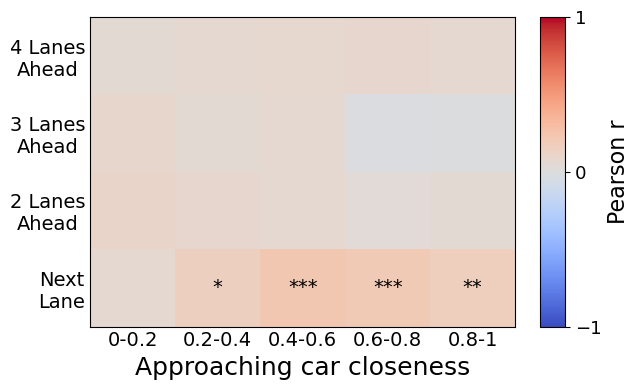

In [93]:
df1, df2 = build_custom_mean_irl_heatmap_dfs(
    subjIds=full_subjIds,
    common_cond = [always_true_cond, move_up, car_density_cond(1), long_road_condition, low_or_mid_penalty_road_cond, not_last_road_condition, outside_crosswalk_cond],
    conds_map = [
        encoming_car_in_front4_thresh_bins(5),
        encoming_car_in_front3_thresh_bins(5),
        encoming_car_in_front2_thresh_bins(5),
        encoming_car_in_front1_thresh_bins(5),
    ],
    verbose=False,
    questionnaire="DOSPERT",
)

feat1_label = "Approaching car closeness" # \n(0 = no car in sight; 1 = directly in front)"
feat1_ticks = ["0-0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8-1"]

feat2_label = ""
feat2_ticks = ["4 Lanes\nAhead", "3 Lanes\nAhead", "2 Lanes\nAhead", "Next\nLane"] #, "Current\nLane"]

cor_title=""
main_font_size = 16

plot_irl_corr_heatmap_poster_figure(
    df2, feat1_label, feat2_label, feat1_ticks=feat1_ticks, feat2_ticks=feat2_ticks, 
    star_only=True, 
    cor_title=cor_title, main_font_size=main_font_size
)

## Save Risk Preference Indicators

In [108]:
col_names = [
    "safest_road_crossing_irl",
    "waiting_for_car_to_pass_irl",

    "high_risk_but_empty_last_road_irl",
    "approaching_crosswalk_in_current_road_irl",
    "approaching_next_crosswalks_irl",
    "move_up_toward_car_irl",
]

conds1=[
    [always_true_cond, car_density_cond(0), inside_crosswalk_cond, last_road_condition, long_road_condition, low_penalty_road_cond, move_up],
    [always_true_cond, car_in_front_N_cond, inside_crosswalk_cond, last_road_condition, low_penalty_road_cond, no_op, safe_zone_cond, short_road_condition],

    [always_true_cond, car_density_cond(0), long_road_condition, outside_crosswalk_cond, crosswalk_not_visible_cond, last_road_condition, high_penalty_road_cond, safe_zone_cond],
    [always_true_cond, car_density_cond(0), danger_zone_cond, long_road_condition, mid_or_high_penalty_road_cond, move_toward_crosswalk_depth1, not_last_road_condition, outside_crosswalk_cond],
    [always_true_cond, car_density_cond(0), danger_zone_cond, long_road_condition, move_toward_next_crosswalks, outside_crosswalk_cond],
    [always_true_cond, encoming_car_in_front1_thresh((0.4, 0.6)), move_up, car_density_cond(1), long_road_condition, low_or_mid_penalty_road_cond, not_last_road_condition, outside_crosswalk_cond],
]

In [109]:
df = pd.read_csv("data/data_integrated.csv", encoding="utf-8-sig")
df_irl = df.copy()

print(f"N={len(df_irl)}")
df_irl.head()

N=282


,subj_id,age,gender,BIS,BIS_motor,BIS_nonplanning,BIS_attentional,BIS_same_response,STAI,STAI_S,...,sideway_movements_toward_visible_crosswalk_safe_zone_cnt_high_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_total_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_easy_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_hard_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_low_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_mid_penalty_session2,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_high_penalty_session2,DDT_mean_log_k,CRA_mean_alpha,web
0,904,22,1,73,23,31,19,-1,87,44,...,91,21,3,18,4,3,14,-3.272599,0.347513,False
1,1000,32,2,61,18,22,21,-1,84,38,...,26,22,2,20,7,8,7,-6.330838,0.660547,False
2,1001,25,2,73,20,31,22,-1,77,38,...,3,14,2,12,2,6,6,-7.961866,0.612792,False
3,1002,21,2,63,22,22,19,-1,73,38,...,64,28,2,26,11,13,4,-1.564452,1.412119,False
4,1003,26,2,69,22,24,23,-1,86,40,...,13,46,2,44,13,16,17,-5.378190,0.668441,False


In [110]:
def irl_reward_list(web, conds = [], reward_condition=None, col_name = None, questionnaire="DOSPERT"):
    if web is None:
        subjIds = full_subjIds
    else:
        subjIds = web_subjIds if web else desktop_subjIds

    questionnaire_full = []
    for subjId in subjIds:
        questionnaire_full.append(df.loc[df["subj_id"] == subjId, questionnaire].item())

    rewards = []
    for subjId in subjIds:
        mean_irl = calculate_mean_IRL_reward_by_conditions(
            subjId,
            conditions=conds,
            reward_condition=reward_condition,
            verbose=False,
            state_only=False,
        )
        rewards.append(mean_irl)

    slope, intercept, r, p, std_err = linregress(rewards, questionnaire_full)
    star = ""
    if not np.isnan(p):
        if p < 0.001:
            star = "***"
        elif p < 0.01:
            star = "**"
        elif p < 0.05:
            star = "*"

    if col_name is not None:
        reward_map = dict(zip(subjIds, rewards))
        mask = df_irl["subj_id"].isin(subjIds)
        df_irl.loc[mask, col_name] = df_irl.loc[mask, "subj_id"].map(reward_map)
        df_irl.to_csv("data/data_integrated_irl.csv", index=False)
    return df_irl

for i in range(len(col_names)):
    col_name = col_names[i]
    conds = conds1[i]
    for web in [False, True, None]:
        df_irl = irl_reward_list(
            web=web,
            conds=conds,
            col_name=col_name,
            questionnaire="DOSPERT",
        )

In [111]:
df_irl.head()

,subj_id,age,gender,BIS,BIS_motor,BIS_nonplanning,BIS_attentional,BIS_same_response,STAI,STAI_S,...,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_high_penalty_session2,DDT_mean_log_k,CRA_mean_alpha,web,safest_road_crossing_irl,waiting_for_car_to_pass_irl,high_risk_but_empty_last_road_irl,approaching_crosswalk_in_current_road_irl,approaching_next_crosswalks_irl,move_up_toward_car_irl
0,904,22,1,73,23,31,19,-1,87,44,...,14,-3.272599,0.347513,False,0.748267,-0.258253,-0.128665,0.608656,0.356492,0.579928
1,1000,32,2,61,18,22,21,-1,84,38,...,7,-6.330838,0.660547,False,0.492620,-0.838224,-0.060370,0.450264,0.492121,0.753004
2,1001,25,2,73,20,31,22,-1,77,38,...,6,-7.961866,0.612792,False,0.663715,0.122388,-1.073019,0.427394,0.443287,0.089030
3,1002,21,2,63,22,22,19,-1,73,38,...,4,-1.564452,1.412119,False,0.223814,-0.900335,0.055749,0.549780,0.407102,0.497768
4,1003,26,2,69,22,24,23,-1,86,40,...,17,-5.378190,0.668441,False,0.464243,-0.561648,0.423064,0.572266,0.436846,0.555052
